# Health02 – Machine-learning triage prediction on the Medical Archive
**Course:** IND310 – Optimization · **Track:** Health (Prof. Habib) · **Project:** Health02 · **Group of 2**

This notebook follows the CRISP-DM structure used in the lectures (*3 Data processing → 4 Modelling → 5 Evaluation → 6 Deployment*) and answers the Health02 questions from the course slides. It starts from the provided notebook *Health_symptoms_patients_generation.ipynb* (patient generator) and extends it.

| Health02 question | Where it is answered |
|---|---|
| Which of the 49 columns are important / irrelevant for triage identification, and why? | §3.1 (selection table), §3.3.3 (association scores), §4.4 (permutation importance, final verdict table) |
| Combine relevant columns for in-depth triage analysis | §3.3.1 (derived attributes, red-flag score) |
| Generate a random list of patients | §3.4 (patient generator, extended from the provided notebook) |
| Can the identified features train an ML model to predict triage patients? (classification **or** regression) | §4 (classification and regression), §5 (patient-level results) |
| Provide context | §1 |
| Applicability of Six Sigma, Lean Six Sigma, optimization techniques, CRISP-DM | §1.5 overview, worked examples in §5.4 (Six Sigma), §5.6 (cost-sensitive optimisation), §5.7 (Lean: waiting-time simulation) |

**How to run:** put `Medical_archieve.csv` next to this notebook (or upload it to `/content` on Colab) and run all cells. All randomness is seeded (`SEED = 42`). Total run time is a few minutes.

# 0. Setup

In [1]:
import os, re, json, math, heapq, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, recall_score, accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report,
                             mean_absolute_error, r2_score, adjusted_mutual_info_score, roc_auc_score, roc_curve)
import sklearn, joblib

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)

try:
    display
except NameError:            # plain-python fallback
    def display(x): print(x)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.1 | numpy 2.1.3 | scikit-learn 1.8.0


# 1. Industrial (business) understanding

## 1.1 Context: what is triage and why does it matter?
Triage is the **sorting and prioritisation of sick or injured people according to their need for emergency care, taking available resources into account** (course PDF *Health_emergency_triage*). Colour-coded systems are the most common: **Red** = immediate, life-threatening; **Yellow** = serious, needs prompt care; **Green** = minor, care can be delayed; Black = deceased / beyond help; White = no injury or illness.
When arrivals exceed capacity, the quality of the sorting decides who waits. Two errors have very different costs:

* **Under-triage** – a patient is given a *lower* urgency than needed (e.g. a red patient labelled green). Potentially fatal delay.
* **Over-triage** – a patient is given a *higher* urgency than needed. Wastes scarce resources (rooms, staff, equipment) and delays other patients.

## 1.2 Objective and data-science goal
* **Industrial objective (stakeholder: an emergency department / triage nurse team):** support the triage decision so that critical patients are recognised first, with *very few under-triaged patients*.
* **Data-science goal (Health02):** use the Medical Archive (diagnosis–symptom records with 49 columns) to (a) find which columns carry triage information, (b) combine them into useful features, (c) generate a random list of patients and (d) test whether an ML model can predict the triage level.

## 1.3 Success criteria (fixed *before* modelling – adjust them if Prof. Habib or your supervisor suggests others)
| ID | Criterion | Threshold (our assumption) |
|---|---|---|
| C1 | Recall of the **High / red** class on rows of *unseen diagnoses* | ≥ 0.90 (≤ 10 % of red cases under-triaged) |
| C2 | Macro-F1 over the three levels on *unseen diagnoses* | ≥ 0.80 |
| C3 | The deployed model uses only features that are **observable or known at triage time** | yes / no |

## 1.4 Assumptions and risks
* **Data unit.** One row of the archive is a *(diagnosis, symptom)* record, **not a patient**. A patient is therefore constructed (§3.4) as a diagnosis plus up to three symptoms revealed in the interview, as in the provided notebook.
* **Triage label.** The archive has no explicit triage colour. We use `Kritiskhet kategori` (Low / Medium / High Hazard) as the triage level: **Low → green, Medium → yellow, High → red**. Black and white have no counterpart in the data. This is an assumption and must be stated in the report.
* **Patient triage = most urgent finding.** A patient's level is the highest level among the symptoms presented (standard triage logic: the most urgent finding decides).
* **Synthetic / simulated data.** The archive comes from a hospital *simulator* (columns such as `WalkAnim`, `ICON`, `ShameLevel`). Results show what is learnable from this archive, **not** clinical performance on real patients.
* **Risks:** label proxies / leakage (`Hazard`, `DiscomfortLevel`), class imbalance, a CSV with multi-line cells, and group structure (many rows per diagnosis → must split by diagnosis).

## 1.5 Applicability of the tools named in the slides
| Tool | How it is used / why it is (or is not) a good fit here |
|---|---|
| **CRISP-DM** | Structures the whole notebook and report (phases 1–6); iterative: findings in §3.2 changed the selection in §3.1. |
| **Six Sigma (DMAIC)** | Define = under-triage of a red patient is the “defect”; Measure = DPMO and sigma level (§5.4); Analyse = which features drive errors (§4.4); Improve = cost-sensitive threshold (§5.6); Control = monitoring plan (§6.2). |
| **Lean Six Sigma** | Waste = over-triage and avoidable waiting. §5.7 simulates the waiting time of red patients with and without model-based priority. Needs real flow data (timestamps, waiting times) to be calibrated – the archive has none. |
| **Optimization techniques** | Constrained model selection (maximise macro-F1 subject to red recall ≥ 0.90, §4.4), a cost-sensitive decision rule (minimise expected cost, §5.6) and a priority-queue policy (§5.7). Resource allocation (rooms/equipment) is a natural extension but is *not* done here. |

# 2. Data understanding (CRISP-DM phase 2)
## 2.1 Collect initial data

In [2]:
CANDIDATE_PATHS = ["Medical_archieve.csv", "/content/Medical_archieve.csv", "data/Medical_archieve.csv",
                   "/mnt/user-data/uploads/Medical_archieve.csv"]
URL = "https://pvexpect.com/Healthcare/Medical_archieve.csv"      # source used in the provided notebook
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), URL)

# NB: semicolon-delimited, UTF-8, contains quoted multi-line cells.
# keep_default_na=False: pandas would otherwise turn the *real* category "None" (= no discomfort) into NaN.
raw = pd.read_csv(DATA_PATH, sep=";", keep_default_na=False, na_values=[""])
raw.columns = raw.columns.str.strip()
raw_default = pd.read_csv(DATA_PATH, sep=";")      # default parsing, only used to document the pitfall in §2.4
raw_default.columns = raw_default.columns.str.strip()
P_COL = [c for c in raw.columns if c.startswith("Sannsynlighet")][0]   # 'probability of critical outcome' column
print("Loaded from:", DATA_PATH)
print("Shape (rows, columns):", raw.shape)
display(raw.head(5))

Loaded from: Medical_archieve.csv
Shape (rows, columns): (3676, 49)


,Diagnosis,Symptom,Examination,Examination_2,Behandlding,Avdeling,Common/uncommon,"Sannsynlighet for kritisk utfall, når symptom er påvist",Kritiskhet kategori,Interview reveal,Symptom.1,ICON,IsMainSymptom,DiscomfortLevel,PatientComplains,Hazard,PatientMobility,Examination 1,Examination 2,Examination 3,Treatment,ShameLevel,WalkAnim,WalkSpeedModifier,CollapseSymptom,RiskOfCollapseStartHours,RiskOfCollapseEndHours,CannotTalk,RiskOfDeathStartHours,RiskOfDeathEndHours,CollapseProcedure,PlanAllTreatments,BleedingLevel,Behandling (Engelsk),Behandling (Norsk),Behandling beskrivelse (Engelsk),Behandling beskrivelse (Norsk),Krav,Surgery room,Diagnoses,Diagnoses_temp,Required Room(s),Departement(s),Required Equipment(s),Legehåndbok,Virtuell sykehus,Kostnader($),Sykdoms beskrivelse (Engelsk),Sykdoms beskrivelse (Norsk)
0,Acute Rheumatic Fever,Rheumatic Fever,an echocardiogram,NaN,antibiotics,Cardiology,Uncommon,100 %,Medium Hazard,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Antibiotics,Antibiotika,Drugs in various forms used to treat various bacterial infections.,Legemidler i ulike former som brukes til å behandle ulike bakterie...,Required room: Any office / Diagnostic unit,False,"Bacterial tonsillitis, Laryngitis, Bronchitis, Bacterial gastroent...",0,"Any office, Diagnostic unit",Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdommer/giktfeber/,0,1100.0,Acute rheumatic fever is an inflammatory disease affecting the hea...,Akutt revmatisk feber er en inflammatorisk sykdom som påvirker hje...
1,Acute Rheumatic Fever,Sore Throat,an interview,an oral cavity inspection,analgesics,Cardiology,Uncommon,70 %,Low Hazard,True,SORE THROAT,0,FALSE,Low,TRUE,Low,MOBILE,INTERVIEW,ORAL CAVITY INSPECTION,0,ANALGESICS,50.0,0,0,0,0,0,0,0,0,0,0.0,0,Analgesics,Analgetika,"Drugs, mostly in pill form, used to relieve pain.","Legemidler, for det meste i pilleform, brukes til å lindre smerte.",Required room: Any office / Diagnostic unit,False,All diseases involving pain.,0,"Any office, Diagnostic unit",Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdommer/giktfeber/,0,1100.0,Acute rheumatic fever is an inflammatory disease affecting the hea...,Akutt revmatisk feber er en inflammatorisk sykdom som påvirker hje...
2,Acute Rheumatic Fever,Muscle and Joint Pain,an interview,a physical examination,rest,Cardiology,Uncommon,70 %,Medium Hazard,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Rest,Hvile,Prescription aimed at avoiding physical exertion in sick patients ...,Resept rettet mot å unngå fysisk anstrengelse hos syke pasienter s...,Required room: Any office / Diagnostic unit,False,0,0,Office or Diagnostic unit,Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdommer/giktfeber/,0,1100.0,Acute rheumatic fever is an inflammatory disease affecting the hea...,Akutt revmatisk feber er en inflammatorisk sykdom som påvirker hje...
3,Acute Rheumatic Fever,Rash,an interview,a physical examination,steroid cream,Cardiology,Uncommon,70 %,Low Hazard,True,RASH,0,FALSE,Low,TRUE,Low,MOBILE,INTERVIEW,PHYSICAL AND VISUAL EXAMINATION,0,STEROID TOPICAL CREAM,50.0,0,0,0,0,0,0,0,0,0,0.0,0,Steroid cream,Steroid krem,"An ointment, lotion, or cream containing corticosteroids (stress h...","En salve, lotion eller krem ​​som inneholder kortikosteroider (str...",Required room: Any office / Diagnostic unit,False,"Athlete's foot, Dermatomyositis",0,Office or Diagnostic unit,Emergency and Orthopeady,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdommer/giktfeber/,0,1100.0,Acute rheumatic fever is an inflammatory disease affecting the hea...,Akutt revmatisk feber er en inflammatorisk sykdom som påvirker hje...
4,Acute Rheumatic Fever,Fever,an interview,temperature measurement,antipyretics,Cardiology,Uncommon,70 %,Medium Hazard,True,FEVER,0,FALSE,Medium,TRUE,Medium,MOBILE,INTERVIEW,TEMPERATURE MEASUREMENT,0,ANTIPYRETICS,40.0,0,0,0,0,0,0,0,0,0,0.0,0,Antipyretics,Antipyretika,Drugs u

## 2.2 Describe data – column dictionary
Each column is assigned to a **group** and (in §3.1) a **role**. The dictionary is built from the course PDF (*Medical_Archieve.csv file* slides) and from inspecting the values.

In [3]:
# group, short meaning, role in the project, reason   (role: ID | TARGET | PROXY | OBS | ARCH | TREAT | DROP)
INFO = {
 "Diagnosis":        ("Key", "Diagnosis name (349 distinct); several rows per diagnosis", "ID", "Group key for splitting and patient generation; not a feature (the model would memorise diagnoses)."),
 "Symptom":          ("Key", "Symptom expected for the diagnosis (611 distinct names)", "ID", "Used to describe patients; 611 levels with ~6 rows each would be memorised."),
 "Symptom.1":        ("Key", "Upper-case copy of Symptom (only rows defined in the simulator)", "DROP", "Duplicate of `Symptom`."),
 "Kritiskhet kategori": ("Label", "Criticality category: Low / Medium / High Hazard", "TARGET", "Used as the triage level (green / yellow / red)."),
 "Hazard":           ("Label", "Hazard Low/Medium/High (simulator copy of the category)", "PROXY", "Near-copy of the target (agrees on every row where both exist) and 24 % missing -> leakage, excluded."),
 "P_COL_PLACEHOLDER": ("Archive knowledge", "Probability of a critical outcome when the symptom is present (%)", "ARCH", "Directly about criticality; kept (cleaned)."),
 "Common/uncommon":  ("Archive knowledge", "How common the symptom/disease is (Common / Uncommon / Rare)", "ARCH", "Prior-probability information; cheap to know."),
 "Avdeling":         ("Archive knowledge", "Department the case belongs to (8 values)", "ARCH", "Related to urgency (Trauma vs Ortho/Emergency); kept as categorical."),
 "Interview reveal": ("Observable", "True if the symptom is revealed in the patient interview", "OBS", "Determines which symptoms a nurse sees first; kept."),
 "Examination":      ("Examination", "First examination needed (62 distinct)", "ARCH", "Turned into counts/flags (n_exam, exam_level)."),
 "Examination_2":    ("Examination", "Second examination (34 % missing)", "ARCH", "Turned into counts/flags."),
 "Examination 1":    ("Examination", "Upper-case copy of Examination", "DROP", "Duplicate."),
 "Examination 2":    ("Examination", "Upper-case copy of Examination_2 (with '0' placeholders)", "DROP", "Duplicate."),
 "Examination 3":    ("Examination", "Third examination (only 'OPHTHALMOSCOPY' x15, else '0')", "DROP", "Almost constant."),
 "IsMainSymptom":    ("Observable", "Is this the main symptom of the diagnosis?", "OBS", "Kept."),
 "DiscomfortLevel":  ("Observable", "Patient discomfort: None / Low / Medium / High ('None' is a real value, see §2.4)", "OBS", "Strong driver of the label (Low->Low, Medium->Medium); possible near-proxy, tested in an ablation (§4.4)."),
 "PatientComplains": ("Observable", "Does the patient complain about it?", "OBS", "Kept."),
 "PatientMobility":  ("Observable", "MOBILE / IMMOBILE / INTUBATED", "OBS", "Classic triage observation."),
 "ShameLevel":       ("Observable", "Embarrassment 0-50 (simulator)", "OBS", "Kept for screening; expected to be irrelevant."),
 "WalkAnim":         ("Simulator", "Walking animation ('limp' / 0)", "DROP", "Graphics label; same information as WalkSpeedModifier."),
 "WalkSpeedModifier":("Observable", "Walking-speed modifier (0 or 0,5 = limping)", "OBS", "Observable gait impairment."),
 "CollapseSymptom":  ("Observable", "Type of collapse the patient may suffer (shock, coma, ...)", "OBS", "Red-flag information."),
 "RiskOfCollapseStartHours": ("Observable", "Hours until the collapse window starts", "OBS", "Time-criticality."),
 "RiskOfCollapseEndHours":   ("Observable", "Hours until the collapse window ends", "OBS", "Time-criticality."),
 "CannotTalk":       ("Observable", "Patient cannot talk", "OBS", "Red flag (airway / consciousness)."),
 "RiskOfDeathStartHours":    ("Observable", "Hours until risk of death starts", "OBS", "Time-criticality; mostly 0."),
 "RiskOfDeathEndHours":      ("Observable", "Hours until risk of death ends", "OBS", "Time-criticality; mostly 0."),
 "BleedingLevel":    ("Observable", "Bleeding level 0-5", "OBS", "Red flag."),
 "CollapseProcedure":("Simulator", "Control procedure applied after collapse (LOW/MEDIUM/...)", "DROP", "Response in the simulator, not a patient observation; overlaps with CollapseSymptom."),
 "ICON":             ("Simulator", "Icon file name", "DROP", "Graphics, irrelevant."),
 "Behandlding":      ("Treatment", "Treatment (169 distinct)", "TREAT", "Consequence of the diagnosis; not known at triage."),
 "Treatment":        ("Treatment", "Upper-case copy of Behandlding", "DROP", "Duplicate."),
 "Behandling (Engelsk)":  ("Treatment", "Treatment name in English", "DROP", "Duplicate of Behandlding / Norwegian translation."),
 "Behandling (Norsk)":    ("Treatment", "Treatment name in Norwegian", "DROP", "Translation."),
 "Behandling beskrivelse (Engelsk)": ("Text", "Treatment description (English)", "DROP", "Free text."),
 "Behandling beskrivelse (Norsk)":   ("Text", "Treatment description (Norwegian)", "DROP", "Free text / translation."),
 "Krav":             ("Treatment", "Requirement text ('Required room: ...', '+')", "DROP", "Free text, redundant with Required Room(s)."),
 "PlanAllTreatments":("Simulator", "Constant 0.0", "DROP", "Constant column – carries no information."),
 "Surgery room":     ("Treatment", "Surgery room required", "TREAT", "Resource need; consequence, not known at triage."),
 "Diagnoses":        ("Treatment", "Group description of diagnoses the treatment fits", "DROP", "Free text about treatments."),
 "Diagnoses_temp":   ("Treatment", "Helper column ('0' / one diagnosis name)", "DROP", "Almost constant helper."),
 "Required Room(s)": ("Treatment", "Room types required (32 distinct; may include ICU)", "TREAT", "Resource need (ICU flag derived); consequence, not known at triage."),
 "Departement(s)":   ("Treatment", "Departments allowed to treat (36 distinct)", "DROP", "Overlaps with Avdeling; 19 % missing."),
 "Required Equipment(s)": ("Treatment", "Constant 0.0", "DROP", "Constant column."),
 "Legehåndbok":      ("Text/links", "Links to the doctor handbook ('#SPILL!' Excel errors)", "DROP", "URLs / spreadsheet errors."),
 "Virtuell sykehus": ("Text/links", "Links to virtual hospital pages", "DROP", "URLs."),
 "Kostnader($)":     ("Treatment", "Treatment cost in USD", "TREAT", "Resource need; consequence, not known at triage."),
 "Sykdoms beskrivelse (Engelsk)": ("Text", "Disease description (English)", "DROP", "Free text."),
 "Sykdoms beskrivelse (Norsk)":   ("Text", "Disease description (Norwegian)", "DROP", "Free text / translation."),
}
INFO[P_COL] = INFO.pop("P_COL_PLACEHOLDER")
assert set(INFO) == set(raw.columns), set(raw.columns) ^ set(INFO)

desc = pd.DataFrame({
    "no": range(1, len(raw.columns) + 1),
    "column": [c if len(c) < 38 else c[:35] + "..." for c in raw.columns],
    "group": [INFO[c][0] for c in raw.columns],
    "dtype": [str(raw[c].dtype) for c in raw.columns],
    "n_unique": [raw[c].nunique() for c in raw.columns],
    "missing_%": [round(100 * raw[c].isna().mean(), 1) for c in raw.columns],
    "meaning": [INFO[c][1] for c in raw.columns],
})
display(desc)
print("\nColumns per group:"); print(desc.group.value_counts().to_string())

,no,column,group,dtype,n_unique,missing_%,meaning
0,1,Diagnosis,Key,str,349,0.0,Diagnosis name (349 distinct); several rows per diagnosis
1,2,Symptom,Key,str,611,0.0,Symptom expected for the diagnosis (611 distinct names)
2,3,Examination,Examination,str,62,1.3,First examination needed (62 distinct)
3,4,Examination_2,Examination,str,57,34.2,Second examination (34 % missing)
4,5,Behandlding,Treatment,str,169,0.0,Treatment (169 distinct)
5,6,Avdeling,Archive knowledge,str,8,0.0,Department the case belongs to (8 values)
6,7,Common/uncommon,Archive knowledge,str,3,0.0,How common the symptom/disease is (Common / Uncommon / Rare)
7,8,"Sannsynlighet for kritisk utfall, n...",Archive knowledge,str,23,0.0,Probability of a critical outcome when the symptom is present (%)
8,9,Kritiskhet kategori,Label,str,5,0.1,Criticality category: Low / Medium / High Hazard
9,10,Interview reveal,Observable,bool,2,0.0,True if the symptom is revealed in the patient interview



Columns per group:
group
Observable           14
Treatment            12
Examination           5
Simulator             4
Text                  4
Key                   3
Archive knowledge     3
Label                 2
Text/links            2


## 2.3 Explore data

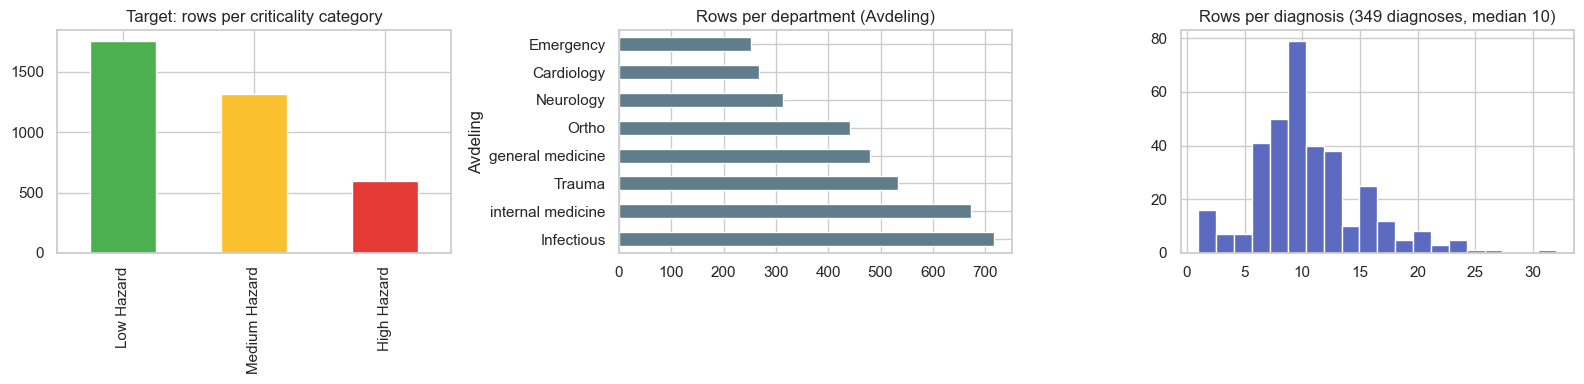

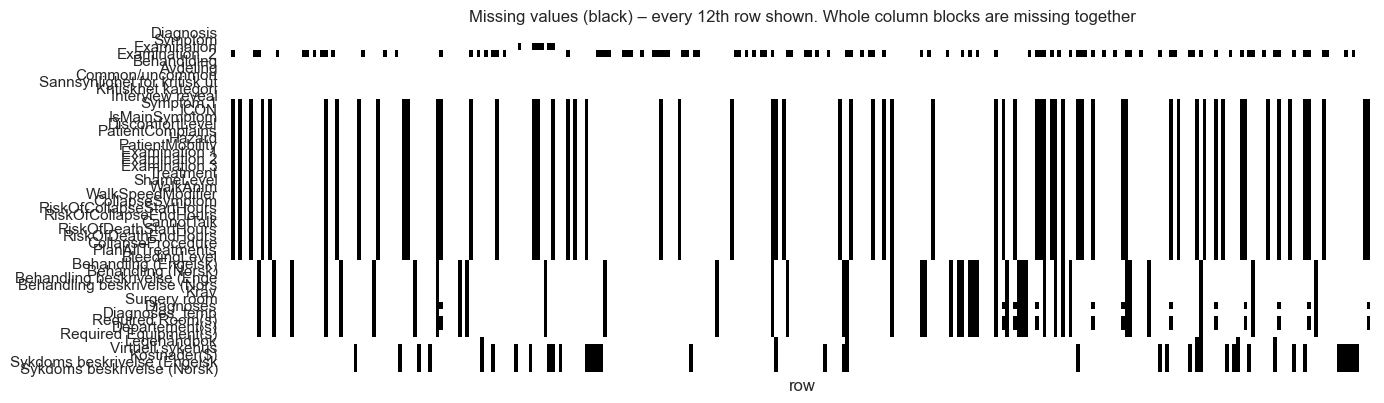

Simulator block (Symptom.1 ... BleedingLevel)           missing rows:   891  (24.2 %)
Treatment block (Behandling ... Sykdoms)                missing rows:   489  (13.3 %)
Room/department block                                   missing rows:   686  (18.7 %)

Are the simulator columns missing on exactly the same rows?  Hazard vs Symptom.1: True | Hazard vs ShameLevel: True
-> columns 11-33 describe the same 2,785 rows (the other 891 rows have no simulator attributes).


In [4]:
TARGET_RAW = "Kritiskhet kategori"
tmp = raw.copy()
tmp[TARGET_RAW] = tmp[TARGET_RAW].astype(str).str.strip()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
order = ["Low Hazard", "Medium Hazard", "High Hazard"]
tmp[TARGET_RAW].value_counts().reindex(order).plot.bar(ax=ax[0], color=["#4caf50", "#fbc02d", "#e53935"])
ax[0].set_title("Target: rows per criticality category"); ax[0].set_xlabel("")
tmp["Avdeling"].str.strip().value_counts().plot.barh(ax=ax[1], color="#607d8b"); ax[1].set_title("Rows per department (Avdeling)")
rows_per_dx = raw.groupby("Diagnosis").size()
ax[2].hist(rows_per_dx, bins=20, color="#5c6bc0"); ax[2].set_title(f"Rows per diagnosis (349 diagnoses, median {int(rows_per_dx.median())})")
plt.tight_layout(); plt.show()

# missingness pattern: which columns are missing on the same rows?
miss = raw.isna()
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(miss.T.iloc[:, ::12], cmap="Greys", cbar=False, ax=ax, yticklabels=[c[:28] for c in raw.columns])
ax.set_title("Missing values (black) – every 12th row shown. Whole column blocks are missing together"); ax.set_xlabel("row"); ax.set_xticks([])
plt.tight_layout(); plt.show()

blocks = {"Simulator block (Symptom.1 ... BleedingLevel)": "Hazard", "Treatment block (Behandling ... Sykdoms)": "Behandling (Engelsk)", "Room/department block": "Required Room(s)"}
for name, col in blocks.items():
    print(f"{name:55s} missing rows: {raw[col].isna().sum():5d}  ({100*raw[col].isna().mean():.1f} %)")
same = raw[["Symptom.1", "Hazard", "DiscomfortLevel", "PatientMobility", "ShameLevel", "BleedingLevel"]].isna()
print("\nAre the simulator columns missing on exactly the same rows?  Hazard vs Symptom.1:", (same["Hazard"] == same["Symptom.1"]).all(),
      "| Hazard vs ShameLevel:", (same["Hazard"] == same["ShameLevel"]).all())
print("-> columns 11-33 describe the same 2,785 rows (the other 891 rows have no simulator attributes).")

## 2.4 Verify data quality
Findings are collected in a table that is reused in the **data-cleaning report** (§3.2).

In [5]:
q = []   # (check, finding, consequence)
dups = raw.duplicated().sum()
q.append(("Exact duplicate rows", f"{dups}", "none removed" if dups == 0 else "remove"))

const = [c for c in raw.columns if raw[c].nunique(dropna=True) <= 1]
q.append(("Constant columns", ", ".join(const), "drop (no information)"))
lowv = [c for c in raw.columns if 1 < raw[c].nunique() and raw[c].astype(str).value_counts(normalize=True).iloc[0] > 0.97 and c not in const]
q.append(("Almost constant columns (>97 % one value)", ", ".join(lowv), "drop / review"))

def same_ci(a, b):
    m = raw[a].notna() & raw[b].notna()
    return m.sum() > 0 and (raw.loc[m, a].astype(str).str.strip().str.upper() == raw.loc[m, b].astype(str).str.strip().str.upper()).mean() > 0.99
pairs = [(a, b) for a, b in [("Symptom", "Symptom.1"), ("Examination", "Examination 1"), ("Examination_2", "Examination 2"), ("Behandlding", "Treatment")] if same_ci(a, b)]
q.append(("Duplicate columns (case-insensitive)", "; ".join(f"{a} = {b}" for a, b in pairs), "keep one"))

ws = {c: int(raw[c].astype(str).str.contains(r"^\s|\s$", regex=True).sum()) for c in [TARGET_RAW]}
q.append(("Leading/trailing blanks in the target", str(ws), "strip"))
q.append(("Target categories (raw)", str(raw[TARGET_RAW].value_counts(dropna=False).to_dict()), "strip -> 3 clean classes, drop 3 missing"))

praw = raw[P_COL].astype(str).str.strip()
is_pct = praw.str.fullmatch(r"-?\d+(\.\d+)? ?%")
bad_text = raw.loc[~is_pct & raw[P_COL].notna(), P_COL]
q.append(("Probability column – text instead of '%' values", f"{len(bad_text)} rows contain description text (cell spill-over from multi-line cells)", "set to missing / inspect rows"))
vals = pd.to_numeric(praw[is_pct].str.replace("%", "").str.strip(), errors="coerce")
q.append(("Probability column – impossible values", f"{int((vals < 0).sum() + (vals > 100).sum())} outside 0-100 (e.g. '-1 %')", "set to missing"))

dc = [c for c in ["RiskOfCollapseStartHours", "RiskOfCollapseEndHours", "RiskOfDeathStartHours", "RiskOfDeathEndHours", "WalkSpeedModifier"]
      if raw[c].astype(str).str.contains(",").any()]
q.append(("Decimal comma in numeric columns", ", ".join(dc), "replace ',' by '.' and convert"))
zero_bool = [c for c in ["IsMainSymptom", "PatientComplains", "Hazard"] if (raw[c].astype(str).str.strip() == "0").any()]
q.append(("Placeholder '0' inside boolean/categorical columns", ", ".join(f"{c} ({(raw[c].astype(str).str.strip()=='0').sum()})" for c in zero_bool), "treat as missing"))
q.append(("Spreadsheet errors", f"'#SPILL!' in Legehåndbok: {(raw['Legehåndbok'].astype(str)=='#SPILL!').sum()} rows", "column dropped"))

both = raw["Hazard"].notna()
agree = (raw.loc[both, "Hazard"].astype(str).str.strip().str.lower() == raw.loc[both, TARGET_RAW].astype(str).str.replace("Hazard", "").str.strip().str.lower())
q.append(("`Hazard` vs target", f"agree on {agree.mean():.1%} of {both.sum()} rows where both exist", "LEAKAGE -> exclude Hazard as a feature"))
within = raw.assign(t=raw[TARGET_RAW].astype(str).str.strip()).groupby("Diagnosis")["t"].nunique()
q.append(("Label granularity", f"{(within > 1).sum()} of {len(within)} diagnoses have rows in more than one category", "label is symptom-level; split by diagnosis"))
ex2 = raw["Examination_2"].dropna().astype(str).str.strip()
q.append(("Examination_2 holds treatment text", f"{int(ex2.str.endswith('.').sum())} values such as 'rest.', 'NSAIDs.', 'Cannot be treated.' (misaligned cells)", "set to missing before building exam features"))
na_swallowed = int(raw_default["DiscomfortLevel"].isna().sum() - raw["DiscomfortLevel"].isna().sum())
q.append(("pandas default NA parsing", f"{na_swallowed} literal 'None' values in DiscomfortLevel (= no discomfort) become NaN with the default read_csv", "read with keep_default_na=False"))
quality = pd.DataFrame(q, columns=["check", "finding", "consequence"])
display(quality)
display(bad_text.to_frame("text found in probability column").assign(Diagnosis=raw.loc[bad_text.index, "Diagnosis"], Symptom=raw.loc[bad_text.index, "Symptom"]).head(6))

,check,finding,consequence
0,Exact duplicate rows,8,remove
1,Constant columns,"PlanAllTreatments, Required Equipment(s)",drop (no information)
2,Almost constant columns (>97 % one value),"Examination 3, CannotTalk, RiskOfDeathStartHours, RiskOfDeathEndHo...",drop / review
3,Duplicate columns (case-insensitive),Symptom = Symptom.1,keep one
4,Leading/trailing blanks in the target,{'Kritiskhet kategori': 3673},strip
5,Target categories (raw),"{' Low Hazard': 1756, ' Medium Hazard': 1315, ' High Hazard ': 592...","strip -> 3 clean classes, drop 3 missing"
6,Probability column – text instead of '%' values,3 rows contain description text (cell spill-over from multi-line c...,set to missing / inspect rows
7,Probability column – impossible values,1 outside 0-100 (e.g. '-1 %'),set to missing
8,Decimal comma in numeric columns,"RiskOfCollapseStartHours, RiskOfCollapseEndHours, RiskOfDeathStart...","replace ',' by '.' and convert"
9,Placeholder '0' inside boolean/categorical columns,"IsMainSymptom (32), PatientComplains (32), Hazard (32)",treat as missing


,text found in probability column,Diagnosis,Symptom
299,T. saginata) are parasitic flatworms living in the digestive syste...,Beef Tapeworm,Beef tapeworms
475,T. solium) are parasitic flatworms living in the digestive system ...,Pork Tapeworm,Pork tapeworms
909,on one or on both sides of the head). The inflammation is caused b...,Mumps,"Mumps also known as Parotitis, is an inflammatory, infectious dise..."


# 3. Data preparation (CRISP-DM phase 3)
Slides *3 Data processing*: **3.1 Select → 3.2 Clean → 3.3 Construct → 3.4 Integrate → 3.5 Format**. Every decision is recorded with its reason.

## 3.1 Select data
Selection by judgement first (does the column bear on triage? is its quality sufficient? is it known at triage time?). The statistical screening in §3.3.3 then *revisits* the selection, as the lecture recommends.

Roles: **ID** (key, not a feature) · **TARGET** · **PROXY** (leaks the label) · **OBS** (observable at the bedside) · **ARCH** (archive knowledge about the symptom/disease) · **TREAT** (treatment/resource consequence – not known at triage) · **DROP** (duplicate, constant, free text, graphics).

In [6]:
sel = pd.DataFrame([(c, INFO[c][0], INFO[c][2], INFO[c][3]) for c in raw.columns], columns=["column", "group", "role", "reason"])
sel["column"] = sel["column"].str.slice(0, 45)
print("Columns per role:"); print(sel.role.value_counts().to_string())
print("\nRationale for inclusion / exclusion of all 49 columns:")
display(sel.sort_values(["role", "column"]).reset_index(drop=True))

Columns per role:
role
DROP      22
OBS       14
ARCH       5
TREAT      4
ID         2
TARGET     1
PROXY      1

Rationale for inclusion / exclusion of all 49 columns:


,column,group,role,reason
0,Avdeling,Archive knowledge,ARCH,Related to urgency (Trauma vs Ortho/Emergency); kept as categorical.
1,Common/uncommon,Archive knowledge,ARCH,Prior-probability information; cheap to know.
2,Examination,Examination,ARCH,"Turned into counts/flags (n_exam, exam_level)."
3,Examination_2,Examination,ARCH,Turned into counts/flags.
4,"Sannsynlighet for kritisk utfall, når symptom",Archive knowledge,ARCH,Directly about criticality; kept (cleaned).
5,Behandling (Engelsk),Treatment,DROP,Duplicate of Behandlding / Norwegian translation.
6,Behandling (Norsk),Treatment,DROP,Translation.
7,Behandling beskrivelse (Engelsk),Text,DROP,Free text.
8,Behandling beskrivelse (Norsk),Text,DROP,Free text / translation.
9,CollapseProcedure,Simulator,DROP,"Response in the simulator, not a patient observation; overlaps wit..."


## 3.2 Clean data
Raw values are cleaned according to the problems found in §2.4. Each step is logged; the log is the **data cleaning report**.

In [7]:
clog = []
def log(step, affected, action): clog.append({"step": step, "rows/values affected": affected, "action": action})

# 1) whitespace
df = raw.apply(lambda s: s.map(lambda v: v.strip() if isinstance(v, str) else v))
df.insert(0, "raw_row", raw.index)
log("Strip leading/trailing blanks", "all text cells", "str.strip()")

# 2) target
LEVELS = ["Low", "Medium", "High"]; COLOUR = {0: "Green", 1: "Yellow", 2: "Red"}
df["triage_level"] = df[TARGET_RAW].map({"Low Hazard": "Low", "Medium Hazard": "Medium", "High Hazard": "High"})
n_no_target = int(df["triage_level"].isna().sum())
df = df[df["triage_level"].notna()].reset_index(drop=True)
df["y"] = df["triage_level"].map({"Low": 0, "Medium": 1, "High": 2}).astype(int)
log("Target: harmonise ' High Hazard' vs 'High Hazard' etc.", f"{len(raw)} rows", "mapped to Low / Medium / High")
log("Target missing", n_no_target, "rows dropped (no label)")

# 3) probability of critical outcome
praw = df[P_COL].astype(str)
is_pct = praw.str.fullmatch(r"-?\d+(\.\d+)? ?%")
p = pd.to_numeric(praw.where(is_pct).str.replace("%", "", regex=False).str.strip(), errors="coerce")
n_text, n_range = int((~is_pct & df[P_COL].notna()).sum()), int(((p < 0) | (p > 100)).sum())
df["p_crit"] = p.mask((p < 0) | (p > 100))
log("Probability column: description text in the cell", n_text, "set to missing (spill-over of multi-line cells)")
log("Probability column: impossible values (<0 or >100)", n_range, "set to missing")

# 4) numeric columns with decimal commas
def to_num(s): return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False).str.strip(), errors="coerce")
num_map = {"ShameLevel": "shame", "BleedingLevel": "bleeding", "WalkSpeedModifier": "walk_mod", "RiskOfCollapseStartHours": "collapse_start",
           "RiskOfCollapseEndHours": "collapse_end", "RiskOfDeathStartHours": "death_start", "RiskOfDeathEndHours": "death_end", "Kostnader($)": "cost"}
for src, dst in num_map.items(): df[dst] = to_num(df[src])
log("Numeric columns stored as text (decimal comma)", f"{len(num_map)} columns", "replace ',' -> '.', convert to float")

# 5) booleans: TRUE/FALSE -> 1/0, '0' placeholders -> missing
def to_bool(s):
    m = {"TRUE": 1, "FALSE": 0}
    return s.map(lambda v: m.get(str(v).strip().upper(), np.nan))
bool_map = {"Interview reveal": "interview", "IsMainSymptom": "is_main", "PatientComplains": "complains", "CannotTalk": "cannot_talk", "Surgery room": "surgery_room"}
n_zero = int((df["IsMainSymptom"].astype(str) == "0").sum())
for src, dst in bool_map.items(): df[dst] = to_bool(df[src])
df["cannot_talk"] = df["cannot_talk"].fillna(df["CannotTalk"].map(lambda v: 0 if str(v).strip() == "0" else np.nan))   # '0' = no
log("Booleans (TRUE/FALSE strings, '0' placeholders)", f"{len(bool_map)} columns, {n_zero} '0' placeholders", "-> 1/0; '0' placeholder -> missing (CannotTalk: '0' = False)")

# 6) categorical columns
def cat(s, zero=np.nan): return s.mask(s.astype(str).eq("0"), zero)
df["discomfort"] = cat(df["DiscomfortLevel"])                       # 'None' is a real value; '0' is a placeholder
df["mobility"] = cat(df["PatientMobility"])
df["collapse_symptom"] = cat(df["CollapseSymptom"], "None")          # '0' = no collapse symptom
df["common"] = df["Common/uncommon"]
df["avdeling"] = df["Avdeling"].str.lower()
log("Categorical placeholders ('0')", f"discomfort/mobility {n_zero} rows; collapse_symptom {(raw['CollapseSymptom'].astype(str)=='0').sum()} rows", "'0'->missing (discomfort, mobility); '0'->'None' (collapse symptom)")

# 7) duplicates
n_dup = int(df.drop(columns=["raw_row"]).duplicated().sum())
log("Duplicate rows", n_dup, "none found" if n_dup == 0 else "removed")
log("Duplicate / constant / free-text columns", f"{(sel.role=='DROP').sum()} columns", "not carried into the modelling frame (see §3.1)")

# 7b) Examination_2 holds treatment text for some rows (misaligned cells)
treat_like = df["Examination_2"].notna() & df["Examination_2"].astype(str).str.endswith(".")
df["exam2_clean"] = df["Examination_2"].mask(treat_like)
log("Examination_2 contains treatment text ('rest.', 'NSAIDs.', 'Cannot be treated.', ...)", int(treat_like.sum()), "set to missing (not an examination)")

# 8) missing values: structural block
n_struct = int(df["Hazard"].isna().sum())
log("Structural missingness (simulator block, same rows in 23 columns)", n_struct, "NOT dropped: numeric -> median + missing-indicator, categorical -> 'missing' (fitted inside the CV folds)")
print(f"Clean frame: {df.shape[0]} rows. Target distribution:"); print(df.triage_level.value_counts().reindex(LEVELS).to_string())

Clean frame: 3673 rows. Target distribution:
triage_level
Low       1756
Medium    1318
High       599


In [8]:
# 9) outliers: simple IQR screen on the numeric columns (domain values are bounded, so we only inspect, not delete)
numcols = ["p_crit", "shame", "bleeding", "walk_mod", "collapse_start", "collapse_end", "death_start", "death_end", "cost"]
rows = []
for c in numcols:
    x = df[c].dropna(); q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()) if iqr > 0 else int((x != x.median()).sum())
    rows.append((c, x.min(), x.median(), x.max(), out))
outl = pd.DataFrame(rows, columns=["column", "min", "median", "max", "values flagged (1.5 IQR)"])
display(outl)
log("Outliers (IQR screen)", int(outl.iloc[:, 4].sum()), "kept: values are bounded domain codes (hours, 0-5 scales, USD cost); tree/forest models are robust to them")
print("Flagged values are legitimate rare states (e.g. long collapse windows, expensive treatments), not entry errors.")
report = pd.DataFrame(clog)
print("\nDATA CLEANING REPORT"); display(report)

,column,min,median,max,values flagged (1.5 IQR)
0,p_crit,0.0,70.0,100.0,163
1,shame,0.0,30.0,90.0,0
2,bleeding,0.0,0.0,5.0,66
3,walk_mod,0.0,0.0,0.5,93
4,collapse_start,0.0,0.0,6.0,329
5,collapse_end,0.0,0.0,24.0,329
6,death_start,0.0,0.0,2.0,48
7,death_end,0.0,0.0,24.0,48
8,cost,100.0,1100.0,10500.0,309


Flagged values are legitimate rare states (e.g. long collapse windows, expensive treatments), not entry errors.

DATA CLEANING REPORT


,step,rows/values affected,action
0,Strip leading/trailing blanks,all text cells,str.strip()
1,Target: harmonise ' High Hazard' vs 'High Hazard' etc.,3676 rows,mapped to Low / Medium / High
2,Target missing,3,rows dropped (no label)
3,Probability column: description text in the cell,0,set to missing (spill-over of multi-line cells)
4,Probability column: impossible values (<0 or >100),1,set to missing
5,Numeric columns stored as text (decimal comma),8 columns,"replace ',' -> '.', convert to float"
6,"Booleans (TRUE/FALSE strings, '0' placeholders)","5 columns, 32 '0' placeholders",-> 1/0; '0' placeholder -> missing (CannotTalk: '0' = False)
7,Categorical placeholders ('0'),discomfort/mobility 32 rows; collapse_symptom 2456 rows,"'0'->missing (discomfort, mobility); '0'->'None' (collapse symptom)"
8,Duplicate rows,8,removed
9,Duplicate / constant / free-text columns,22 columns,not carried into the modelling frame (see §3.1)


**Unresolved problems and their likely effect (part of the cleaning report):**
* The 891 rows without simulator attributes are not missing at random (mostly symptoms that restate a diagnosis); imputing them means the model partly learns “no information → average class”. We keep a missing-indicator and check the effect in §5.5 (scenario analysis).
* A few rows contain text spilled from multi-line cells in the probability column – other cells of those rows may be shifted too; their probability is set to missing, the rows are kept.
* `Hazard` is excluded (leakage). `DiscomfortLevel` is kept but treated with caution (§3.3.3, §4.4).

## 3.3 Construct data
### 3.3.1 Derived attributes (combining columns for triage analysis)
The slides ask us to *combine relevant columns*. We construct:

| New attribute | Built from | Triage rationale |
|---|---|---|
| `n_exam`, `exam_level` | `Examination`, `Examination_2` | How demanding the work-up is: 0 = interview only, 1 = bedside examination, 2 = instrumental / laboratory / imaging |
| `has_collapse`, `collapse_window` | `CollapseSymptom`, `RiskOfCollapse*Hours` | Danger of sudden deterioration and how long the window lasts |
| `has_death_risk` | `RiskOfDeath*Hours` | Explicit risk of death |
| `immobile` | `PatientMobility` | IMMOBILE / INTUBATED |
| **`red_flag_score`** | `cannot_talk + immobile + (bleeding>0) + has_collapse + has_death_risk` | One combined, easily explainable bedside score (0-5). Deliberately **excludes** `DiscomfortLevel` |
| `icu_required`, `surgery_room`, `cost` | `Required Room(s)`, `Surgery room`, `Kostnader($)` | Treatment-side consequences (not available at triage time) |

In [9]:
print("Examination names in the archive (after removing treatment text):"); print(sorted(set(df["Examination"].dropna()) | set(df["exam2_clean"].dropna())))

Examination names in the archive (after removing treatment text):
['CBC testing', 'CSF analysis', 'CT enterography', 'ELISA testing', 'FAST', 'ICU blood analysis', 'PCR testing', 'RT-PCR testing', 'USG', 'a CRP test', 'a CT scan', 'a back X-ray', 'a barium swallow', 'a blood test', 'a chest X-ray', 'a chest X-ray, an MRI scan, or a CT scan', 'a head X-ray', 'a lower limb X-ray', 'a nasal cavity inspection', 'a physical examination', 'a skin allergy test', 'a sweat chloride test', 'abdominal palpation', 'an ECG', 'an EEG', 'an EMG', 'an MRI scan', 'an ear examination', 'an echocardiogram', 'an evaluation', 'an interview', 'an interview, a basic visual test, or ophthalmoscopy', 'an interview, heart monitoring, or an ECG', 'an oral cavity inspection', 'an upper limb X-ray', 'an urgent echocardiogram', 'an urgent echocardiogram, an echocardiogram, or angiography', 'angiography', 'audiometry', 'biopsy testing', 'blood pressure measurement', 'chest auscultation', 'elastase testing', 'fungal 

In [10]:
def exam_level(a, b):
    # 0 = interview only, 1 = bedside examination (physical, inspection, auscultation, ...), 2 = instrumental / laboratory / imaging
    BEDSIDE = r"physical|inspection|palpation|auscultation|percussion|measurement|visual"
    lv = []
    for e in (a, b):
        if not isinstance(e, str): continue
        e = e.lower()
        lv.append(0 if "interview" in e else (1 if re.search(BEDSIDE, e) else 2))
    return max(lv) if lv else np.nan

df["n_exam"] = df[["Examination", "exam2_clean"]].notna().sum(axis=1)
df["exam_level"] = [exam_level(a, b) for a, b in zip(df["Examination"], df["exam2_clean"])]
df["has_collapse"] = np.where(df["collapse_symptom"].isna(), np.nan, (df["collapse_symptom"] != "None").astype(float))
df["collapse_window"] = df["collapse_end"] - df["collapse_start"]
df["has_death_risk"] = np.where(df["death_end"].isna(), np.nan, (df["death_end"] > 0).astype(float))
df["immobile"] = np.where(df["mobility"].isna(), np.nan, df["mobility"].isin(["IMMOBILE", "INTUBATED"]).astype(float))
df["red_flag_score"] = (df[["cannot_talk", "immobile", "has_collapse", "has_death_risk"]].fillna(0).sum(axis=1) + (df["bleeding"].fillna(0) > 0))
df["icu_required"] = df["Required Room(s)"].astype(str).str.contains("ICU").astype(float).where(df["Required Room(s)"].notna())
df["discomfort_ord"] = df["discomfort"].map({"None": 0, "Low": 1, "Medium": 2, "High": 3})

print("exam_level distribution:", df.exam_level.value_counts().sort_index().to_dict())
print("\nMean triage level (0 green .. 2 red) by red_flag_score:")
display(df.groupby("red_flag_score").agg(rows=("y", "size"), mean_level=("y", "mean"), share_red=("y", lambda s: (s == 2).mean())).round(2))

exam_level distribution: {0.0: 471, 1.0: 2230, 2.0: 927}

Mean triage level (0 green .. 2 red) by red_flag_score:


,rows,mean_level,share_red
red_flag_score,,,
0.0,3268,0.53,0.07
1.0,220,1.84,0.86
2.0,103,2.00,1.00
3.0,79,2.00,1.00
4.0,3,2.00,1.00


### 3.3.2 Transformations and the label
* The label is the ordinal level **Low = 0 → green, Medium = 1 → yellow, High = 2 → red** (`y`).
* **Patient level:** a patient's level is the *maximum* over the symptoms presented (§3.4).
* Two modelling targets are used in §4: the three-class level (**classification**) and the ordinal score `y` (**regression**, thresholded back to levels).
* Scaling/encoding is done *inside* the modelling pipelines so that nothing is learned from validation data.

### 3.3.3 Revisit selection – statistical screening of candidate columns
For every candidate column (roles OBS, ARCH, TREAT, PROXY and the new attributes) we measure the association with the triage level:
* **Adjusted mutual information (AMI)** – works for numeric and categorical variables, corrected for chance; numeric variables are binned into ≤ 5 quantile groups, *missing is treated as its own category*.
* **Cramér's V** with the χ² p-value (categorical association, 0 = none, 1 = perfect).

The slides stress that single-variable scores are not enough because two variables can repeat each other – so we also inspect the correlation among the numeric candidates.

,candidate,AMI,Cramers_V,chi2_p,missing_%
0,Hazard (PROXY),0.631,0.844,0.0e+00,24.2
1,DiscomfortLevel,0.404,0.655,0.0e+00,25.0
2,has_collapse*,0.274,0.544,0.0e+00,24.2
3,red_flag_score*,0.272,0.515,0.0e+00,0.0
4,CollapseSymptom,0.251,0.542,0.0e+00,24.2
5,RiskOfCollapseStart,0.115,0.410,1.9e-261,24.2
6,RiskOfCollapseEnd,0.115,0.410,1.9e-261,24.2
7,collapse_window*,0.115,0.410,1.9e-261,24.2
8,Interview reveal,0.099,0.415,1.1e-138,0.0
9,PatientMobility,0.092,0.316,1.0e-156,25.0


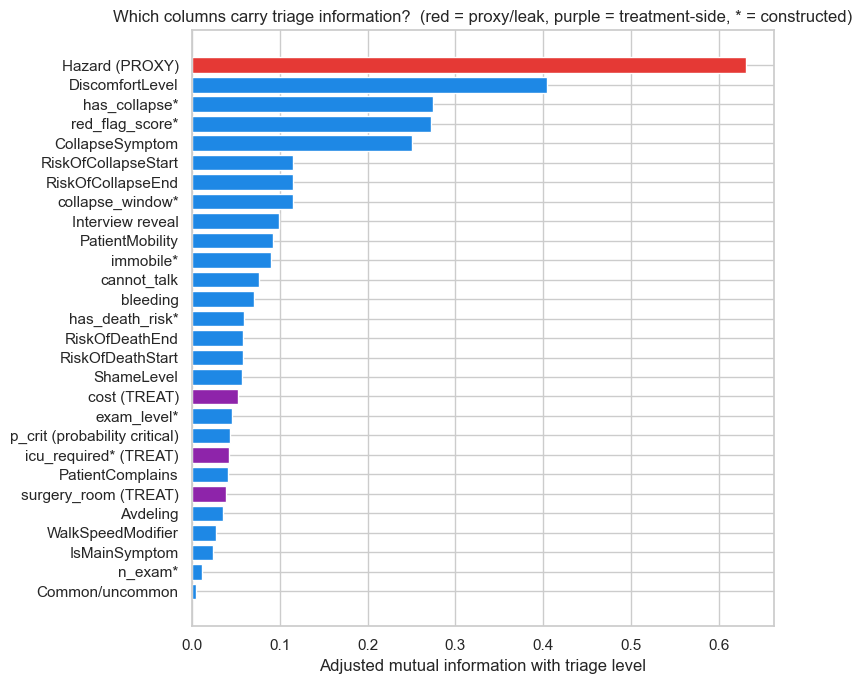

In [11]:
cand = {  # screening name -> column in df (after cleaning / construction)
 "Hazard (PROXY)": "Hazard", "DiscomfortLevel": "discomfort", "PatientMobility": "mobility", "CollapseSymptom": "collapse_symptom",
 "has_collapse*": "has_collapse", "red_flag_score*": "red_flag_score", "immobile*": "immobile", "cannot_talk": "cannot_talk", "bleeding": "bleeding",
 "RiskOfCollapseStart": "collapse_start", "RiskOfCollapseEnd": "collapse_end", "collapse_window*": "collapse_window", "RiskOfDeathStart": "death_start",
 "RiskOfDeathEnd": "death_end", "has_death_risk*": "has_death_risk", "ShameLevel": "shame", "WalkSpeedModifier": "walk_mod", "IsMainSymptom": "is_main",
 "PatientComplains": "complains", "Interview reveal": "interview", "p_crit (probability critical)": "p_crit", "Common/uncommon": "common", "Avdeling": "avdeling",
 "n_exam*": "n_exam", "exam_level*": "exam_level", "icu_required* (TREAT)": "icu_required", "surgery_room (TREAT)": "surgery_room", "cost (TREAT)": "cost",
}
def as_cat(s):
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 6:
        s = pd.qcut(s.rank(method="first"), q=5, labels=False).where(s.notna())
    return s.astype(object).where(s.notna(), "missing").astype(str)

def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2, pval, *_ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1)); r_, k_ = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return math.sqrt(phi2 / max(1e-9, min(k_ - 1, r_ - 1))), pval

y_cat = df["y"].astype(str)
rows = []
for name, col in cand.items():
    xc = as_cat(df[col]); v, pv = cramers_v(xc, y_cat)
    rows.append((name, col, round(adjusted_mutual_info_score(xc, y_cat), 3), round(v, 3), pv, round(100 * df[col].isna().mean(), 1)))
screen = pd.DataFrame(rows, columns=["candidate", "col", "AMI", "Cramers_V", "chi2_p", "missing_%"]).sort_values("AMI", ascending=False).reset_index(drop=True)
screen_show = screen.drop(columns="col").assign(chi2_p=screen["chi2_p"].map(lambda v: f"{v:.1e}"))
display(screen_show)

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#e53935" if "PROXY" in n else "#8e24aa" if "TREAT" in n else "#1e88e5" for n in screen.candidate[::-1]]
ax.barh(screen.candidate[::-1], screen.AMI[::-1], color=colors)
ax.set_xlabel("Adjusted mutual information with triage level"); ax.set_title("Which columns carry triage information?  (red = proxy/leak, purple = treatment-side, * = constructed)")
plt.tight_layout(); plt.show()

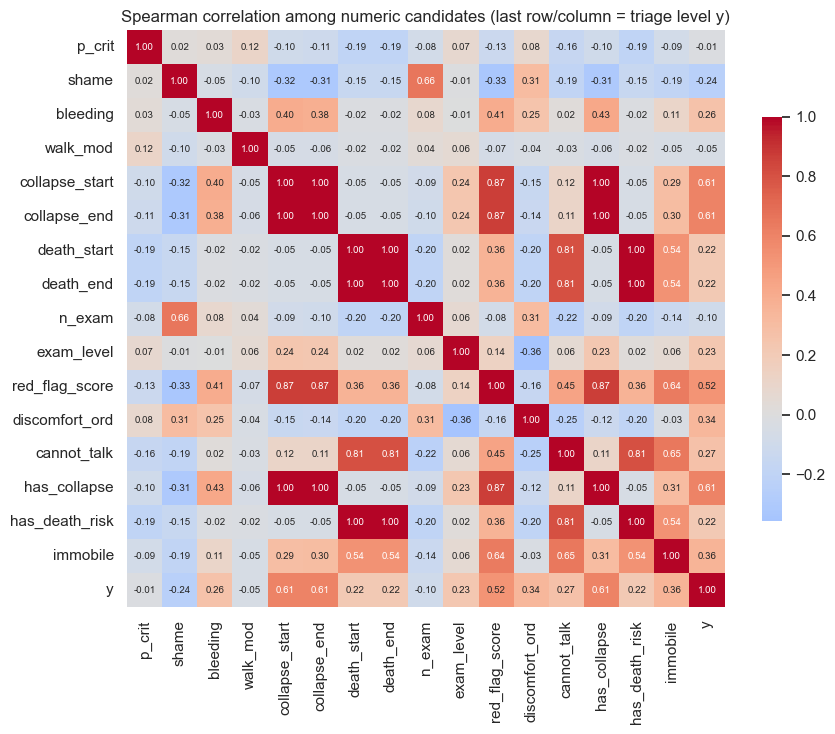

Highly redundant pairs (|rho| > 0.8):
death_start     has_death_risk    1.00
death_end       has_death_risk    1.00
death_start     death_end         1.00
collapse_end    has_collapse      1.00
collapse_start  collapse_end      1.00
                has_collapse      1.00
red_flag_score  has_collapse      0.87
collapse_start  red_flag_score    0.87
collapse_end    red_flag_score    0.87
cannot_talk     has_death_risk    0.81
death_start     cannot_talk       0.81
death_end       cannot_talk       0.81


In [12]:
numeric_cand = ["p_crit", "shame", "bleeding", "walk_mod", "collapse_start", "collapse_end", "death_start", "death_end", "n_exam", "exam_level",
                "red_flag_score", "discomfort_ord", "cannot_talk", "has_collapse", "has_death_risk", "immobile", "y"]
corr = df[numeric_cand].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation among numeric candidates (last row/column = triage level y)")
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().loc[lambda s: s.abs() > 0.8].sort_values(key=abs, ascending=False)
print("Highly redundant pairs (|rho| > 0.8):"); print(pairs.round(2).to_string() if len(pairs) else "none")

## 3.4 Integrate data – from archive rows to patients (random patient list)
The provided notebook generates a patient by choosing a random diagnosis and up to three interview-revealed symptoms. We keep that logic and **integrate** the archive into a patient table (aggregation across several rows, as in the lecture on data integration). Changes compared with the provided notebook:

1. The patient keeps **row references**, so every presented symptom carries all engineered features (the original kept only name, hazard, symptoms and diagnosis).
2. Each patient gets a **ground-truth triage level** = highest level among the presented symptoms (`true_level`) and, for analysis only, the highest level of the *whole* diagnosis (`true_level_full`, what the interview could not reveal).
3. `get_possible_diagnoses_probability` had its `return` commented out and re-downloaded the CSV on every call – it is rewritten (`possible_diagnoses`) and works on the loaded table.
4. Generation is **seeded**; arrival times use the time-slot logic of the original (with a fixed year and a seeded generator). `Planned` is kept for compatibility but not used.

In [13]:
from datetime import datetime, timedelta

DAYS_OF_WEEK = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
TIME_SLOTS = [f"{d} {t}" for d in DAYS_OF_WEEK for t in ["9:00 AM - 12:00 PM", "12:00 PM - 3:00 PM", "3:00 PM - 6:00 PM"]]

def generate_arrival_time(slot, week_of_year, rng, year=2026):
    # Random arrival time inside a weekly time slot (logic from the provided notebook, seeded).
    day_name, time_range = slot.split(" ", 1)
    start_s, end_s = time_range.split(" - ")
    ref = datetime(year, 1, 4)
    day = ref + timedelta(weeks=week_of_year - 1, days=DAYS_OF_WEEK.index(day_name) - ref.weekday())
    d = day.strftime("%Y-%m-%d")
    start = datetime.strptime(f"{d} {start_s}", "%Y-%m-%d %I:%M %p"); end = datetime.strptime(f"{d} {end_s}", "%Y-%m-%d %I:%M %p")
    return start + timedelta(seconds=int(rng.integers(0, int((end - start).total_seconds()) + 1)))

FIRST = ["Anna", "Jonas", "Mina", "Erik", "Sara", "Lars", "Nora", "Ola", "Ida", "Tobias", "Emma", "Henrik", "Sofie", "Magnus", "Julie", "Kristian", "Maja", "Anders", "Thea", "Mats"]
LAST = ["Hansen", "Johansen", "Olsen", "Larsen", "Andersen", "Pedersen", "Nilsen", "Kristiansen", "Jensen", "Karlsen", "Berg", "Haugen", "Eriksen", "Dahl", "Lund"]
dx_rows = {dx: g.index.to_numpy() for dx, g in df.groupby("Diagnosis")}
ALL_DX = np.array(sorted(dx_rows))

def generate_patient(rng, diagnoses, pid):
    dx = diagnoses[int(rng.integers(len(diagnoses)))]
    idx = dx_rows[dx]
    revealed = idx[df.loc[idx, "interview"].to_numpy() == 1]
    fallback = len(revealed) == 0                      # diagnosis without any interview-revealed symptom
    pool = idx if fallback else revealed
    pres = rng.choice(pool, size=min(3, len(pool)), replace=False)
    slot = TIME_SLOTS[int(rng.integers(len(TIME_SLOTS)))]
    return {"patient_id": pid, "Name": f"{FIRST[int(rng.integers(len(FIRST)))]} {LAST[int(rng.integers(len(LAST)))]}",
            "Planned": bool(rng.integers(2)), "Diagnosis": dx, "slot": slot,
            "arrival_time": generate_arrival_time(slot, int(rng.integers(1, 53)), rng),
            "presented_rows": [int(i) for i in pres], "Revealed_Symptoms": df.loc[pres, "Symptom"].tolist(),
            "Unrevealed_Symptoms": df.loc[idx[df.loc[idx, "interview"].to_numpy() == 0], "Symptom"].tolist(),
            "true_level": int(df.loc[pres, "y"].max()), "true_level_full": int(df.loc[idx, "y"].max()), "fallback": fallback}

def generate_patients(n, diagnoses=ALL_DX, seed=SEED):
    rng = np.random.default_rng(seed)
    P = pd.DataFrame([generate_patient(rng, diagnoses, i + 1) for i in range(n)])
    P["n_symptoms"] = P.presented_rows.map(len)
    P["max_red_flag_score"] = P.presented_rows.map(lambda r: df.loc[r, "red_flag_score"].max())
    P["max_p_crit"] = P.presented_rows.map(lambda r: df.loc[r, "p_crit"].max())
    P["true_colour"] = P.true_level.map(COLOUR)
    return P

patients_demo = generate_patients(15, seed=SEED)
print("Random list of 15 patients (ground truth = most urgent presented symptom):")
display(patients_demo[["patient_id", "Name", "arrival_time", "Diagnosis", "Revealed_Symptoms", "n_symptoms", "max_red_flag_score", "true_colour"]])

Random list of 15 patients (ground truth = most urgent presented symptom):


,patient_id,Name,arrival_time,Diagnosis,Revealed_Symptoms,n_symptoms,max_red_flag_score,true_colour
0,1,Magnus Larsen,2026-07-06 14:55:37,Babesiosis,"[Fatigue, Dry Cough, Malaise]",3,0.0,Green
1,2,Tobias Kristiansen,2026-03-07 17:46:49,Portal Vein Thrombosis,"[Tenderness, Abdominal Pain, Swelling]",3,0.0,Yellow
2,3,Sara Johansen,2026-11-19 09:11:29,Renal Contusion,"[Spasms, Vomiting, Nausea]",3,0.0,Yellow
3,4,Ola Johansen,2026-06-12 17:40:46,Simple Fracture of Fibula,"[Bruise, Pain, Redness]",3,0.0,Yellow
4,5,Anna Jensen,2026-09-24 14:02:57,Pacific Coast Tick Fever,"[Eschar, Muscle Pain, Rash]",3,0.0,Yellow
5,6,Ola Johansen,2026-10-18 12:34:06,Thalassaemia,"[Pale Skin, Dark Urine, Jaundice]",3,0.0,Green
6,7,Nora Larsen,2026-08-27 11:49:16,Hypertensive Retinopathy,"[Swollen Eyelids, Headache]",2,0.0,Yellow
7,8,Kristian Eriksen,2026-10-14 11:31:31,Hemothorax,"[Dizziness, Chest Injury, Cyanosis]",3,0.0,Yellow
8,9,Maja Olsen,2025-12-29 17:23:26,Giant Cells Arteritis,"[Fatigue, Fever, Loss of Vision]",3,0.0,Yellow
9,10,Henrik Nilsen,2026-07-25 12:06:42,Respiratory Crypto,"[Hoarseness, Irritable Cough, Nasal Congestion]",3,0.0,Green


In [14]:
# Differential diagnosis from the revealed symptoms (rewritten version of get_possible_diagnoses_probability)
sym_by_dx = df.groupby("Diagnosis")["Symptom"].apply(set).to_dict()
def possible_diagnoses(revealed_symptoms):
    revealed = set(revealed_symptoms); rows = []
    for dx, syms in sym_by_dx.items():
        hit = len(revealed & syms)
        if hit == len(revealed):                                # every revealed symptom is expected for this diagnosis
            rows.append((dx, hit, len(syms), round(hit / len(syms), 2)))
    return pd.DataFrame(rows, columns=["Diagnosis", "matched", "symptoms_in_archive", "Probability"]).sort_values(["Probability", "Diagnosis"], ascending=[False, True]).reset_index(drop=True)

for _, pt in patients_demo.head(2).iterrows():
    cand_dx = possible_diagnoses(pt.Revealed_Symptoms)
    print(f"Patient {pt.patient_id}: revealed {pt.Revealed_Symptoms}  | true diagnosis: {pt.Diagnosis}  | {len(cand_dx)} candidate diagnoses")
    display(cand_dx.head(4))

big = generate_patients(500, seed=SEED + 1)
n_cand = big.Revealed_Symptoms.map(lambda s: len(possible_diagnoses(s)))
print(f"\nOver 500 random patients: median {int(n_cand.median())} candidate diagnoses per patient; unique diagnosis for {(n_cand == 1).mean():.0%}.")
print("-> The interview often does not identify the diagnosis, so triage must work on the symptom level, not only on the diagnosis.")

Patient 1: revealed ['Fatigue', 'Dry Cough', 'Malaise']  | true diagnosis: Babesiosis  | 1 candidate diagnoses


,Diagnosis,matched,symptoms_in_archive,Probability
0,Babesiosis,3,9,0.33


Patient 2: revealed ['Tenderness', 'Abdominal Pain', 'Swelling']  | true diagnosis: Portal Vein Thrombosis  | 1 candidate diagnoses


,Diagnosis,matched,symptoms_in_archive,Probability
0,Portal Vein Thrombosis,3,8,0.38



Over 500 random patients: median 2 candidate diagnoses per patient; unique diagnosis for 36%.
-> The interview often does not identify the diagnosis, so triage must work on the symptom level, not only on the diagnosis.


## 3.5 Format data
The modelling tools need a flat table with identifiers first and the target last. We define the **feature sets** (grouped by what is known when) and save the modelling frame and its data dictionary.

| Feature block | Meaning | Known at triage? |
|---|---|---|
| **FS1 – bedside observations** | interview, main symptom, complains, cannot talk, shame, bleeding, gait, collapse and death-risk information, mobility, red-flag score | yes |
| **FS2 = FS1 + DiscomfortLevel** | adds the strongest single column (possible near-proxy) | yes (but suspicious) |
| **FS3 = FS2 + archive knowledge** | probability of critical outcome, commonness, department, examination demand | yes (from the knowledge base) |
| **FS4 = FS3 + treatment-side** | ICU requirement, surgery room, cost | **no** – consequence of the diagnosis; used only as an upper bound |

In [15]:
OBS_NUM = ["interview", "is_main", "complains", "cannot_talk", "shame", "bleeding", "walk_mod", "collapse_start", "collapse_end", "collapse_window",
           "death_start", "death_end", "has_collapse", "has_death_risk", "immobile", "red_flag_score"]
OBS_CAT = ["mobility", "collapse_symptom"]
DISC_CAT = ["discomfort"]
ARCH_NUM = ["p_crit", "n_exam", "exam_level"]
ARCH_CAT = ["common", "avdeling"]
TREAT_NUM = ["icu_required", "surgery_room", "cost"]

FEATURE_SETS = {
    "FS1 bedside observations":                 (OBS_NUM, OBS_CAT),
    "FS2 + DiscomfortLevel":                    (OBS_NUM, OBS_CAT + DISC_CAT),
    "FS3 + archive knowledge":                  (OBS_NUM + ARCH_NUM, OBS_CAT + DISC_CAT + ARCH_CAT),
    "FS4 + treatment-side (not known at triage)": (OBS_NUM + ARCH_NUM + TREAT_NUM, OBS_CAT + DISC_CAT + ARCH_CAT),
}
ALL_FEATURES = FEATURE_SETS["FS4 + treatment-side (not known at triage)"][0] + FEATURE_SETS["FS4 + treatment-side (not known at triage)"][1]

model_frame = df[["raw_row", "Diagnosis", "Symptom"] + ALL_FEATURES + ["triage_level", "y"]].copy()     # ids first, target last
model_frame.to_csv(f"{OUT_DIR}/triage_model_frame.csv", index=False)
report.to_csv(f"{OUT_DIR}/data_cleaning_report.csv", index=False)
sel.to_csv(f"{OUT_DIR}/column_selection_table.csv", index=False)
screen_show.to_csv(f"{OUT_DIR}/feature_screening.csv", index=False)
print("Modelling frame:", model_frame.shape, "-> saved to", f"{OUT_DIR}/triage_model_frame.csv")
print("Missing share per feature (structural block = ~24 %):")
print((model_frame[ALL_FEATURES].isna().mean() * 100).round(1).sort_values(ascending=False).head(12).to_string())
for k, (n_, c_) in FEATURE_SETS.items(): print(f"{k:45s}: {len(n_) + len(c_):2d} features")

Modelling frame: (3673, 32) -> saved to outputs/triage_model_frame.csv
Missing share per feature (structural block = ~24 %):
complains           25.0
discomfort          25.0
immobile            25.0
is_main             25.0
mobility            25.0
has_death_risk      24.2
death_start         24.2
collapse_symptom    24.2
has_collapse        24.2
death_end           24.2
collapse_window     24.2
collapse_end        24.2
FS1 bedside observations                     : 18 features
FS2 + DiscomfortLevel                        : 19 features
FS3 + archive knowledge                      : 24 features
FS4 + treatment-side (not known at triage)   : 27 features


# 4. Modelling (CRISP-DM phase 4)
Slides *4 Modelling*: **4.1 Select technique → 4.2 Generate test design → 4.3 Build model → 4.4 Assess model**.

## 4.1 Select modelling technique
The Health02 question allows *classification or regression*. We use both:

| Task | Target | Techniques | Why |
|---|---|---|---|
| **Classification** (main) | triage level Low / Medium / High (green / yellow / red) | majority-class baseline, logistic regression, decision tree, random forest, gradient boosting | Linear → tree → ensemble ladder from the lecture appendix; the tree gives readable rules, the forest handles interactions and missing-indicators. |
| **Regression** | ordinal urgency score `y` ∈ {0, 1, 2}, cut at 0.5 / 1.5 | ridge regression, random-forest regressor | Keeps the order of the levels; the cut-offs can later be moved to trade under- against over-triage (§5.6). |

### 4.1.1 Assumptions of the techniques compared with the data description

In [16]:
# Make categorical columns plain object dtype (robust across pandas/sklearn versions)
for c in OBS_CAT + DISC_CAT + ARCH_CAT:
    df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

num_all = OBS_NUM + ARCH_NUM
rho = df[num_all].corr(method="spearman").abs().where(lambda m: ~np.eye(len(m), dtype=bool))
n_hi = int((rho.stack() > 0.9).sum() // 2)
class_share = df.y.value_counts(normalize=True).sort_index()
assump = pd.DataFrame([
 ("Rows are independent (all techniques)", f"{df.Diagnosis.nunique()} diagnoses, median {int(df.groupby('Diagnosis').size().median())} rows each -> rows of one diagnosis are NOT independent", "split and cross-validate by diagnosis (group-wise)"),
 ("Balanced classes (all)", "shares Low/Medium/High = " + " / ".join(f"{v:.0%}" for v in class_share), "class weights + report recall per class, not only accuracy"),
 ("No missing values (logistic regression, ridge, sklearn trees)", f"{df[ALL_FEATURES].isna().any(axis=1).mean():.0%} of rows have a missing feature (structural block)", "median imputation + missing-indicator; 'missing' category"),
 ("Little multicollinearity (logistic regression, ridge)", f"{n_hi} feature pairs with |Spearman rho| > 0.9 (e.g. collapse start/end, death start/end)", "L2 regularisation; trees are insensitive"),
 ("Features on comparable scales (logistic regression, ridge)", "hours, 0-5 scales, USD cost differ by orders of magnitude", "standardise numeric features inside the pipeline"),
 ("Linear effect on the logit (logistic regression)", "interactions between flags are likely (a red flag matters more together with immobility)", "also fit tree models; compare"),
 ("Enough data for the number of features (all)", f"{len(df)} rows, {len(ALL_FEATURES)} raw features", "regularised / shallow models; check for over-fitting through held-out diagnoses"),
], columns=["assumption (technique)", "check against the data description", "action"])
display(assump)

,assumption (technique),check against the data description,action
0,Rows are independent (all techniques),"349 diagnoses, median 10 rows each -> rows of one diagnosis are NO...",split and cross-validate by diagnosis (group-wise)
1,Balanced classes (all),shares Low/Medium/High = 48% / 36% / 16%,"class weights + report recall per class, not only accuracy"
2,"No missing values (logistic regression, ridge, sklearn trees)",45% of rows have a missing feature (structural block),median imputation + missing-indicator; 'missing' category
3,"Little multicollinearity (logistic regression, ridge)",9 feature pairs with |Spearman rho| > 0.9 (e.g. collapse start/end...,L2 regularisation; trees are insensitive
4,"Features on comparable scales (logistic regression, ridge)","hours, 0-5 scales, USD cost differ by orders of magnitude",standardise numeric features inside the pipeline
5,Linear effect on the logit (logistic regression),interactions between flags are likely (a red flag matters more tog...,also fit tree models; compare
6,Enough data for the number of features (all),"3673 rows, 27 raw features",regularised / shallow models; check for over-fitting through held-...


## 4.2 Generate test design
Defined **before** building (lecture 4.2): 

* **Hold-out test set:** 20 % of the *diagnoses* (never seen during development), stratified by class. It is used once, in §5.1.
* **Development set (80 %):** repeated, stratified, **group-wise 5-fold cross-validation** (3 repeats with different fold assignments) for all comparisons, tuning and feature decisions. No diagnosis appears in both the training and validation part of a fold – the model must predict the triage level of diagnoses it has never seen.
* **Metrics:** macro-F1 (all three levels count equally), **recall of the red class** (an under-triaged red patient is the costly error), under-triage rate (prediction lower than truth), over-triage rate (prediction higher than truth), accuracy and balanced accuracy for completeness, ROC-AUC. Accuracy alone is misleading for imbalanced classes (lecture 3.1).
* **Reporting:** mean ± standard deviation over the 3 repeats.

In [17]:
import time
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_pos, test_pos = next(sgkf.split(df, df.y, df.Diagnosis))        # 1 of 5 folds = 20 % of the diagnoses as test set
dev, test = df.iloc[dev_pos], df.iloc[test_pos]
assert not set(dev.Diagnosis) & set(test.Diagnosis)
split_tab = pd.DataFrame({"rows": [len(dev), len(test)], "diagnoses": [dev.Diagnosis.nunique(), test.Diagnosis.nunique()],
                          **{f"share {l}": [ (dev.triage_level == l).mean().round(3), (test.triage_level == l).mean().round(3)] for l in LEVELS}},
                         index=["development (cross-validation)", "hold-out test (used once, §5.1)"])
display(split_tab)

N_REPEATS = 3
MODEL_COL = {"Dummy (majority class)": "#9e9e9e", "Logistic regression": "#0072B2", "Decision tree": "#E69F00", "Random forest": "#009E73",
             "Gradient boosting": "#CC79A7", "Random forest (tuned)": "#D55E00", "Ridge regression": "#56B4E9", "RF regressor": "#8c564b"}
LEVEL_COL = {"Low": "#43a047", "Medium": "#f2b01e", "High": "#d32f2f"}

def make_pre(nums, cats, scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(num_steps), nums),
                              ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                                                ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]), cats)])

RF_BASE = dict(n_estimators=150, min_samples_leaf=3, max_features="sqrt")
RF_TUNED = {}
def make_model(name, rf_params=None):
    if name == "Dummy (majority class)": return DummyClassifier(strategy="most_frequent")
    if name == "Logistic regression":    return LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0)
    if name == "Decision tree":          return DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, class_weight="balanced", random_state=SEED)
    if name == "Random forest":          return RandomForestClassifier(**{**RF_BASE, **(rf_params or {})}, class_weight="balanced", n_jobs=-1, random_state=SEED)
    if name == "Random forest (tuned)":  return RandomForestClassifier(**{**RF_BASE, **RF_TUNED}, class_weight="balanced", n_jobs=-1, random_state=SEED)
    if name == "Gradient boosting":      return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.1, max_iter=80, class_weight="balanced", random_state=SEED)
    raise ValueError(name)

def level_metrics(y, pred):
    rec = recall_score(y, pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
            "recall_low": rec[0], "recall_medium": rec[1], "recall_high": rec[2],
            "under_triage": float((pred < y).mean()), "over_triage": float((pred > y).mean())}

def cv_classify(model_name, fs, data=None, repeats=N_REPEATS, seed0=SEED, rf_params=None, label=None):
    # Group-wise stratified CV on the development set. fs = name in FEATURE_SETS or a (numeric, categorical) tuple.
    data = dev if data is None else data
    nums, cats = FEATURE_SETS[fs] if isinstance(fs, str) else fs
    X, y, g = data[nums + cats], data["y"].to_numpy(), data["Diagnosis"].to_numpy()
    rows, oof_first, secs = [], None, []
    for r in range(repeats):
        proba = np.zeros((len(data), 3))
        for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=seed0 + r).split(X, y, g):
            pipe = Pipeline([("pre", make_pre(nums, cats, scale=(model_name == "Logistic regression"))), ("m", make_model(model_name, rf_params))])
            t0 = time.perf_counter(); pipe.fit(X.iloc[tr], y[tr]); secs.append(time.perf_counter() - t0)
            proba[va] = pipe.predict_proba(X.iloc[va])
        m = level_metrics(y, proba.argmax(1)); m["roc_auc_ovr"] = roc_auc_score(y, proba, multi_class="ovr")
        rows.append(m)
        if r == 0: oof_first = proba
    R = pd.DataFrame(rows)
    out = {"model": model_name, "features": label or (fs if isinstance(fs, str) else "custom"), "n_features": len(nums) + len(cats), "fit_s": float(np.mean(secs))}
    out.update({k: R[k].mean() for k in R}); out.update({k + "_sd": R[k].std(ddof=0) for k in R})
    return out, oof_first

RESULTS, OOF = [], {}
def run(model_name, fs, **kw):
    res, oof = cv_classify(model_name, fs, **kw)
    RESULTS.append(res); OOF[(res["model"], res["features"])] = oof
    return res

def show_cols(T, extra=()):
    c = ["model", "features", "n_features", "macro_f1", "macro_f1_sd", "recall_high", "recall_high_sd", "under_triage", "over_triage", "accuracy", "roc_auc_ovr", "fit_s", *extra]
    return T[c].round(3)
print("Test design ready. Development rows:", len(dev), "| test rows:", len(test))

,rows,diagnoses,share Low,share Medium,share High
development (cross-validation),2943,279,0.478,0.359,0.163
"hold-out test (used once, §5.1)",730,70,0.478,0.358,0.164


Test design ready. Development rows: 2943 | test rows: 730


## 4.3 Build model
### 4.3.1–4.3.2 Initial parameters and reasons
Start with default-like values (lecture 4.3.1), documenting the reason for every choice:

| Model | Parameter settings | Reason |
|---|---|---|
| Majority-class baseline | most frequent class | Reference: what a model without information achieves (≈ 48 % accuracy, 0 red recall). |
| Logistic regression | L2, C = 1, `class_weight="balanced"`, standardised inputs | Interpretable linear benchmark; balanced weights because red cases are the minority. |
| Decision tree | depth ≤ 6, ≥ 10 rows per leaf, balanced weights | Readable rules; depth/leaf size limit over-fitting to single diagnoses. |
| Random forest | 150 trees, ≥ 3 rows per leaf, √p features per split, balanced weights; **tuned in §4.3.3** | Handles interactions and missing indicators without scaling. |
| Gradient boosting | depth 4, learning rate 0.1, 80 iterations, balanced weights | Sequential ensemble (like AdaBoost in the lecture appendix) as a stronger non-linear benchmark. |

Features: **FS3** (everything known at triage) is the reference set; the feature sets are compared in §4.3.4.

In [18]:
t0 = time.time()
for m in ["Dummy (majority class)", "Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]:
    run(m, "FS3 + archive knowledge")
T_models = pd.DataFrame(RESULTS)
display(show_cols(T_models))
print(f"({time.time() - t0:.0f} s)")

,model,features,n_features,macro_f1,macro_f1_sd,recall_high,recall_high_sd,under_triage,over_triage,accuracy,roc_auc_ovr,fit_s
0,Dummy (majority class),FS3 + archive knowledge,24,0.216,0.000,0.000,0.000,0.522,0.000,0.478,0.500,0.013
1,Logistic regression,FS3 + archive knowledge,24,0.847,0.001,0.912,0.005,0.032,0.107,0.861,0.973,0.079
2,Decision tree,FS3 + archive knowledge,24,0.835,0.003,0.892,0.004,0.032,0.117,0.851,0.969,0.016
3,Random forest,FS3 + archive knowledge,24,0.885,0.001,0.919,0.005,0.032,0.070,0.898,0.985,0.130
4,Gradient boosting,FS3 + archive knowledge,24,0.883,0.002,0.914,0.009,0.032,0.072,0.896,0.985,1.077


(21 s)


### 4.3.3 Tune the random forest (revised parameter settings)
A small grid over leaf size, depth and the number of features per split. Tuning uses its **own fold assignment** (different seed) on the development set only; the decision rule is the project's own success criterion: *maximise macro-F1 subject to red recall ≥ 0.90* (a constrained optimisation, see §1.5). The hold-out test set is untouched.

In [19]:
t0 = time.time()
grid = [dict(min_samples_leaf=l, max_depth=d, max_features=f) for l in (1, 3, 8) for d in (None, 10) for f in ("sqrt", 0.5)]
rows = []
for p in grid:
    r, _ = cv_classify("Random forest", "FS3 + archive knowledge", repeats=1, seed0=SEED + 100, rf_params=p)
    rows.append({**p, "macro_f1": r["macro_f1"], "recall_high": r["recall_high"], "under_triage": r["under_triage"], "over_triage": r["over_triage"], "fit_s": r["fit_s"]})
G = pd.DataFrame(rows)
G["feasible (red recall >= 0.90)"] = G.recall_high >= 0.90
best_cfg = (G[G["feasible (red recall >= 0.90)"]] if G["feasible (red recall >= 0.90)"].any() else G).sort_values("macro_f1", ascending=False).iloc[0]
RF_TUNED = {"min_samples_leaf": int(best_cfg.min_samples_leaf), "max_depth": None if pd.isna(best_cfg.max_depth) else int(best_cfg.max_depth),
            "max_features": best_cfg.max_features if isinstance(best_cfg.max_features, str) else float(best_cfg.max_features)}
display(G.sort_values("macro_f1", ascending=False).round(3))
print("Selected random-forest parameters:", RF_TUNED, f"({time.time() - t0:.0f} s)")

,min_samples_leaf,max_depth,max_features,macro_f1,recall_high,under_triage,over_triage,fit_s,feasible (red recall >= 0.90)
7,3,10.0,0.5,0.893,0.923,0.028,0.068,0.148,True
3,1,10.0,0.5,0.892,0.908,0.031,0.066,0.144,True
1,1,NaN,0.5,0.891,0.914,0.031,0.065,0.151,True
0,1,NaN,sqrt,0.890,0.908,0.033,0.063,0.133,True
5,3,NaN,0.5,0.889,0.946,0.026,0.073,0.140,True
2,1,10.0,sqrt,0.887,0.904,0.034,0.065,0.150,True
4,3,NaN,sqrt,0.886,0.933,0.031,0.071,0.130,True
11,8,10.0,0.5,0.883,0.933,0.027,0.078,0.149,True
9,8,NaN,0.5,0.883,0.937,0.027,0.078,0.142,True
6,3,10.0,sqrt,0.879,0.929,0.030,0.078,0.142,True


Selected random-forest parameters: {'min_samples_leaf': 3, 'max_depth': 10, 'max_features': 0.5} (10 s)


### 4.3.4 Run the techniques on every feature set
The tuned forest and the logistic regression are run on the four feature sets of §3.5, to answer *which columns matter* from the model's point of view and to detect leakage.

In [20]:
t0 = time.time()
for fs in FEATURE_SETS:
    run("Random forest (tuned)", fs)
for fs in ["FS1 bedside observations", "FS2 + DiscomfortLevel", "FS3 + archive knowledge", "FS4 + treatment-side (not known at triage)"]:
    run("Logistic regression", fs)
run("Decision tree", "FS1 bedside observations")
RES = pd.DataFrame(RESULTS).drop_duplicates(["model", "features"], keep="last").reset_index(drop=True)
display(show_cols(RES[RES.model.isin(["Random forest (tuned)", "Logistic regression"])].sort_values(["model", "features"])))
print(f"({time.time() - t0:.0f} s)")

,model,features,n_features,macro_f1,macro_f1_sd,recall_high,recall_high_sd,under_triage,over_triage,accuracy,roc_auc_ovr,fit_s
8,Logistic regression,FS1 bedside observations,18,0.588,0.003,0.923,0.000,0.247,0.137,0.616,0.771,0.058
9,Logistic regression,FS2 + DiscomfortLevel,19,0.822,0.002,0.923,0.000,0.025,0.136,0.839,0.962,0.052
10,Logistic regression,FS3 + archive knowledge,24,0.847,0.001,0.912,0.005,0.032,0.107,0.861,0.973,0.066
11,Logistic regression,FS4 + treatment-side (not known at triage),27,0.876,0.001,0.913,0.008,0.041,0.072,0.886,0.982,0.057
4,Random forest (tuned),FS1 bedside observations,18,0.660,0.003,0.923,0.000,0.129,0.222,0.649,0.825,0.132
5,Random forest (tuned),FS2 + DiscomfortLevel,19,0.821,0.002,0.921,0.001,0.025,0.136,0.839,0.962,0.131
6,Random forest (tuned),FS3 + archive knowledge,24,0.888,0.002,0.919,0.014,0.029,0.070,0.901,0.985,0.133
7,Random forest (tuned),FS4 + treatment-side (not known at triage),27,0.919,0.004,0.954,0.003,0.024,0.048,0.927,0.991,0.134


(14 s)


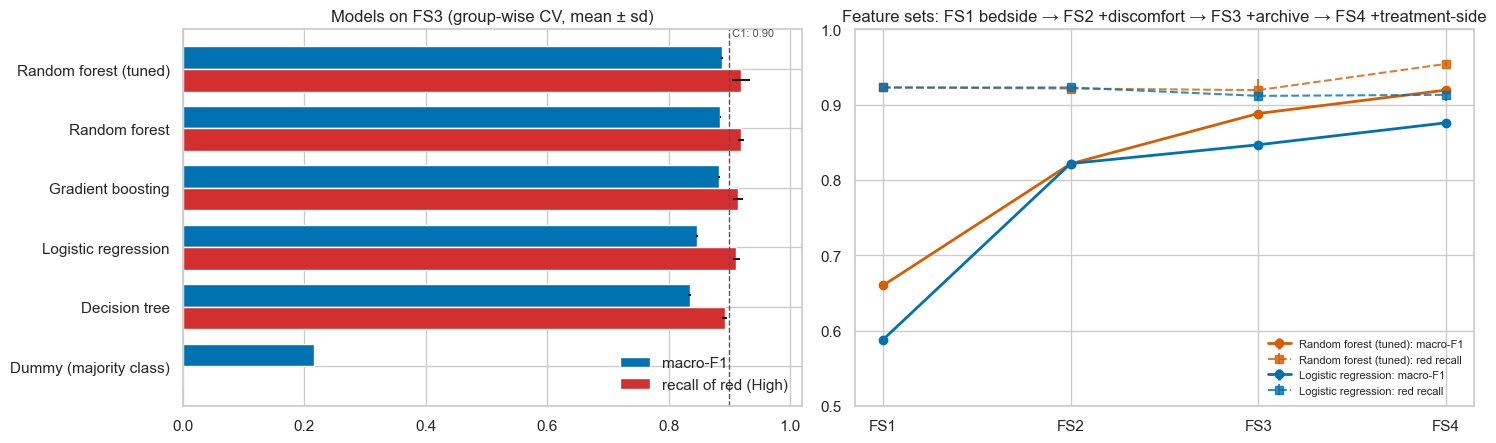

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
T3 = RES[RES.features == "FS3 + archive knowledge"].sort_values("macro_f1")
y_ = np.arange(len(T3)); h = 0.38
ax[0].barh(y_ + h / 2, T3.macro_f1, h, xerr=T3.macro_f1_sd, color="#0072B2", label="macro-F1")
ax[0].barh(y_ - h / 2, T3.recall_high, h, xerr=T3.recall_high_sd, color="#d32f2f", label="recall of red (High)")
ax[0].axvline(0.90, color="#555", ls="--", lw=1); ax[0].text(0.90, len(T3) - 0.45, " C1: 0.90", fontsize=8, color="#555")
ax[0].set_yticks(y_); ax[0].set_yticklabels(T3.model); ax[0].set_xlim(0, 1.02); ax[0].legend(loc="lower right", frameon=False)
ax[0].set_title("Models on FS3 (group-wise CV, mean ± sd)")

order = ["FS1 bedside observations", "FS2 + DiscomfortLevel", "FS3 + archive knowledge", "FS4 + treatment-side (not known at triage)"]
short = ["FS1", "FS2", "FS3", "FS4"]
for name, col in [("Random forest (tuned)", MODEL_COL["Random forest (tuned)"]), ("Logistic regression", MODEL_COL["Logistic regression"])]:
    S_ = RES[RES.model == name].set_index("features").reindex(order)
    ax[1].errorbar(short, S_.macro_f1, yerr=S_.macro_f1_sd, marker="o", color=col, label=f"{name}: macro-F1", lw=2)
    ax[1].errorbar(short, S_.recall_high, yerr=S_.recall_high_sd, marker="s", ls="--", color=col, label=f"{name}: red recall", lw=1.5, alpha=.8)
ax[1].set_ylim(0.5, 1.0); ax[1].set_title("Feature sets: FS1 bedside → FS2 +discomfort → FS3 +archive → FS4 +treatment-side"); ax[1].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 4.3.5 Describe the resulting model
All models are scikit-learn pipelines: *imputation (+ missing indicators) → one-hot encoding (→ scaling for linear models) → estimator*. The random forest is an ensemble of 150 fully grown trees (leaf size 1, half of the features per split) with balanced class weights. Its behaviour is described by importance analyses and by a shallow, readable tree in §4.4.

## 4.4 Assess model
### 4.4.1–4.4.4 Evaluation criteria, comparison and selection of the best model
Selection follows the success criteria of §1.3 as a **constrained optimisation**: *maximise macro-F1 subject to red recall ≥ 0.90 (C1) and macro-F1 ≥ 0.80 (C2), using only features known at triage (C3)*. 

Because `DiscomfortLevel` is suspiciously informative (§3.3.3), a feature set **without** it (FS3b) is added. **Decision rule:** if a model without `DiscomfortLevel` meets C1 and C2 it is preferred; otherwise the best model that meets them is taken and the dependence on `DiscomfortLevel` is reported as a limitation.

In [22]:
FS3B = "FS3b archive + bedside, no DiscomfortLevel"
FEATURE_SETS[FS3B] = (OBS_NUM + ARCH_NUM, OBS_CAT + ARCH_CAT)
t0 = time.time()
for m in ["Random forest (tuned)", "Logistic regression", "Gradient boosting", "Decision tree"]:
    run(m, FS3B)
RES = pd.DataFrame(RESULTS).drop_duplicates(["model", "features"], keep="last").reset_index(drop=True)

NO_DISC = ["FS1 bedside observations", FS3B]
cand_tab = RES[(~RES.features.str.startswith("FS4")) & (RES.model != "Dummy (majority class)")].copy()
cand_tab["uses_DiscomfortLevel"] = ~cand_tab.features.isin(NO_DISC)
cand_tab["C1 red recall>=0.90"] = cand_tab.recall_high >= 0.90
cand_tab["C2 macro-F1>=0.80"] = cand_tab.macro_f1 >= 0.80
cand_tab["feasible"] = cand_tab["C1 red recall>=0.90"] & cand_tab["C2 macro-F1>=0.80"]
display(cand_tab.sort_values("macro_f1", ascending=False)[["model", "features", "macro_f1", "recall_high", "under_triage", "over_triage", "roc_auc_ovr", "uses_DiscomfortLevel", "C1 red recall>=0.90", "C2 macro-F1>=0.80", "feasible"]].round(3))

feasible = cand_tab[cand_tab.feasible]
pool = feasible[~feasible.uses_DiscomfortLevel] if len(feasible[~feasible.uses_DiscomfortLevel]) else feasible
if not len(pool): pool = cand_tab.sort_values(["recall_high", "macro_f1"], ascending=False).head(1)
BEST = pool.sort_values("macro_f1", ascending=False).iloc[0]
BEST_MODEL, BEST_FS = BEST.model, BEST.features
FINAL_NUMS, FINAL_CATS = FEATURE_SETS[BEST_FS]
bd = cand_tab[(cand_tab.model == "Random forest (tuned)")].set_index("features")
print(f"({time.time() - t0:.0f} s)")
print("\nBest model WITHOUT DiscomfortLevel (tuned RF, FS3b): macro-F1 %.3f, red recall %.3f -> C1 %s, C2 %s" %
      (bd.loc[FS3B, "macro_f1"], bd.loc[FS3B, "recall_high"], "met" if bd.loc[FS3B, "recall_high"] >= .9 else "NOT met", "met" if bd.loc[FS3B, "macro_f1"] >= .8 else "NOT met"))
print("Best model WITH DiscomfortLevel (tuned RF, FS3):    macro-F1 %.3f, red recall %.3f" % (bd.loc['FS3 + archive knowledge', 'macro_f1'], bd.loc['FS3 + archive knowledge', 'recall_high']))
print(f"\nSELECTED: {BEST_MODEL} on '{BEST_FS}'  (macro-F1 {BEST.macro_f1:.3f} ± {BEST.macro_f1_sd:.3f}, red recall {BEST.recall_high:.3f} ± {BEST.recall_high_sd:.3f}, "
      f"under-triage {BEST.under_triage:.3f}, over-triage {BEST.over_triage:.3f})")
print("Uses DiscomfortLevel:", bool(BEST.uses_DiscomfortLevel))

,model,features,macro_f1,recall_high,under_triage,over_triage,roc_auc_ovr,uses_DiscomfortLevel,C1 red recall>=0.90,C2 macro-F1>=0.80,feasible
6,Random forest (tuned),FS3 + archive knowledge,0.888,0.919,0.029,0.070,0.985,True,True,True,True
2,Random forest,FS3 + archive knowledge,0.885,0.919,0.032,0.070,0.985,True,True,True,True
3,Gradient boosting,FS3 + archive knowledge,0.883,0.914,0.032,0.072,0.985,True,True,True,True
10,Logistic regression,FS3 + archive knowledge,0.847,0.912,0.032,0.107,0.973,True,True,True,True
1,Decision tree,FS3 + archive knowledge,0.835,0.892,0.032,0.117,0.969,True,False,True,False
9,Logistic regression,FS2 + DiscomfortLevel,0.822,0.923,0.025,0.136,0.962,True,True,True,True
5,Random forest (tuned),FS2 + DiscomfortLevel,0.821,0.921,0.025,0.136,0.962,True,True,True,True
13,Random forest (tuned),"FS3b archive + bedside, no DiscomfortLevel",0.756,0.914,0.115,0.144,0.896,False,True,False,False
15,Gradient boosting,"FS3b archive + bedside, no DiscomfortLevel",0.751,0.930,0.111,0.154,0.890,False,True,False,False
16,Decision tree,"FS3b archive + bedside, no DiscomfortLevel",0.693,0.913,0.115,0.222,0.839,False,True,False,False


(18 s)

Best model WITHOUT DiscomfortLevel (tuned RF, FS3b): macro-F1 0.756, red recall 0.914 -> C1 met, C2 NOT met
Best model WITH DiscomfortLevel (tuned RF, FS3):    macro-F1 0.888, red recall 0.919

SELECTED: Random forest (tuned) on 'FS3 + archive knowledge'  (macro-F1 0.888 ± 0.002, red recall 0.919 ± 0.014, under-triage 0.029, over-triage 0.070)
Uses DiscomfortLevel: True


**Multi-criteria decision analysis (MCDA, lecture 4.4.4).** The constrained rule above looks at predictive performance only. As a robustness check, the candidate models on the selected feature set are also ranked with a weighted sum of min–max-normalised criteria: macro-F1 (0.30), red recall (0.30), low over-triage (0.15), interpretability (0.15; our 1–5 judgement) and training speed (0.10).

In [23]:
INTERPRET = {"Logistic regression": 4, "Decision tree": 5, "Random forest": 2, "Random forest (tuned)": 2, "Gradient boosting": 1}
M = RES[(RES.features == BEST_FS) & (RES.model != "Dummy (majority class)")].copy().set_index("model")
mm = lambda s, inv=False: (1 - (s - s.min()) / (s.max() - s.min() + 1e-12)) if inv else (s - s.min()) / (s.max() - s.min() + 1e-12)
crit = pd.DataFrame({"macro-F1": mm(M.macro_f1), "red recall": mm(M.recall_high), "low over-triage": mm(M.over_triage, inv=True),
                     "interpretability": mm(pd.Series({m: INTERPRET[m] for m in M.index})), "speed": mm(M.fit_s, inv=True)})
W = pd.Series({"macro-F1": .30, "red recall": .30, "low over-triage": .15, "interpretability": .15, "speed": .10})
crit["MCDA score"] = crit[W.index].mul(W).sum(axis=1)
display(crit.sort_values("MCDA score", ascending=False).round(3))
print("MCDA winner:", crit["MCDA score"].idxmax(), "| constrained-optimisation winner:", BEST_MODEL)

,macro-F1,red recall,low over-triage,interpretability,speed,MCDA score
Random forest (tuned),1.000,1.000,0.998,0.25,0.890,0.876
Random forest,0.939,1.000,1.000,0.25,0.893,0.858
Gradient boosting,0.906,0.821,0.964,0.00,0.000,0.663
Logistic regression,0.226,0.718,0.209,0.75,0.953,0.522
Decision tree,0.000,0.000,0.000,1.00,1.000,0.250


MCDA winner: Random forest (tuned) | constrained-optimisation winner: Random forest (tuned)


### 4.4.5 Interpret results in industrial terms – confusion matrix, ROC, per-class recall
Out-of-fold predictions on the development set: every prediction comes from a model that **never saw that diagnosis**.

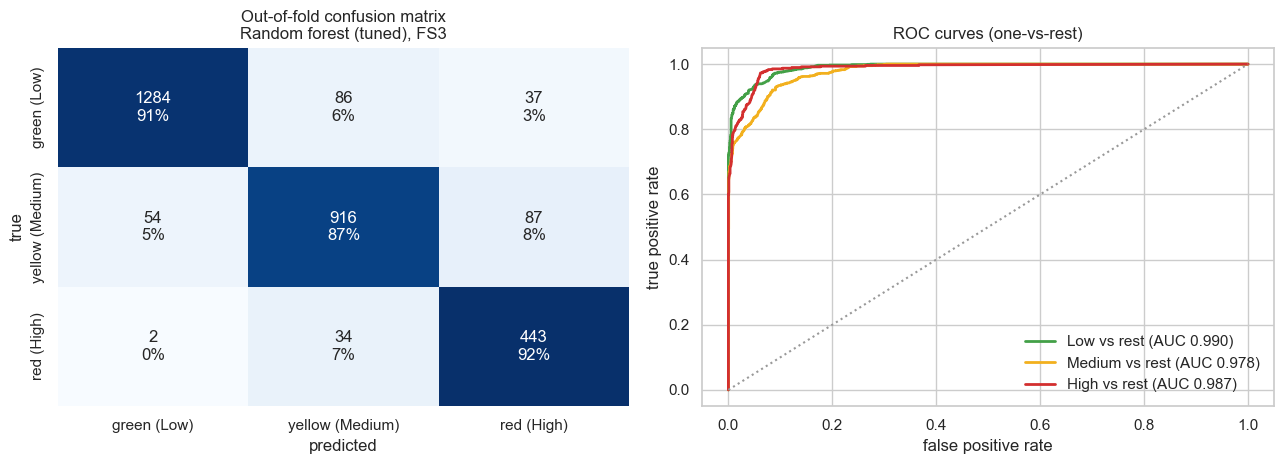

                 precision    recall  f1-score   support

    Low (green)      0.958     0.913     0.935      1407
Medium (yellow)      0.884     0.867     0.875      1057
     High (red)      0.781     0.925     0.847       479

       accuracy                          0.898      2943
      macro avg      0.875     0.901     0.886      2943
   weighted avg      0.903     0.898     0.899      2943

Red cases classified as lower urgency: 36 of 479  (7.5%);  of these classified GREEN: 2


In [24]:
oof = OOF[(BEST_MODEL, BEST_FS)]; y_dev = dev.y.to_numpy(); pred_dev = oof.argmax(1)
cm = confusion_matrix(y_dev, pred_dev, labels=[0, 1, 2])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=np.array([[f"{cm[i, j]}\n{cm[i, j] / cm[i].sum():.0%}" for j in range(3)] for i in range(3)]), fmt="", cmap="Blues",
            xticklabels=["green (Low)", "yellow (Medium)", "red (High)"], yticklabels=["green (Low)", "yellow (Medium)", "red (High)"], cbar=False, ax=ax[0])
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title(f"Out-of-fold confusion matrix\n{BEST_MODEL}, {BEST_FS.split(' ')[0]}")
for k, l in enumerate(LEVELS):
    fpr, tpr, _ = roc_curve((y_dev == k).astype(int), oof[:, k]); ax[1].plot(fpr, tpr, color=LEVEL_COL[l], lw=2, label=f"{l} vs rest (AUC {roc_auc_score((y_dev == k).astype(int), oof[:, k]):.3f})")
ax[1].plot([0, 1], [0, 1], color="#999", ls=":"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].legend(frameon=False, loc="lower right"); ax[1].set_title("ROC curves (one-vs-rest)")
plt.tight_layout(); plt.show()
print(classification_report(y_dev, pred_dev, target_names=["Low (green)", "Medium (yellow)", "High (red)"], digits=3))
under_red = ((pred_dev < 2) & (y_dev == 2)).sum(); print(f"Red cases classified as lower urgency: {under_red} of {(y_dev == 2).sum()}  ({under_red / (y_dev == 2).sum():.1%});"
      f"  of these classified GREEN: {((pred_dev == 0) & (y_dev == 2)).sum()}")

### 4.4.3 Regression option: predict the ordinal urgency score
The second modelling option in the Health02 question. The regressors predict `y` ∈ {0, 1, 2}; predictions are cut at 0.5 and 1.5 to get levels. Same group-wise CV.

,model,features,MAE,R2,macro_f1,recall_high,under_triage,over_triage,accuracy
0,Ridge regression,FS3 + archive knowledge,0.215,0.727,0.813,0.592,0.088,0.076,0.836
1,RF regressor,FS3 + archive knowledge,0.130,0.845,0.883,0.768,0.059,0.045,0.896
2,Random forest (tuned) (classifier),FS3 + archive knowledge,NaN,NaN,0.888,0.919,0.029,0.070,0.901


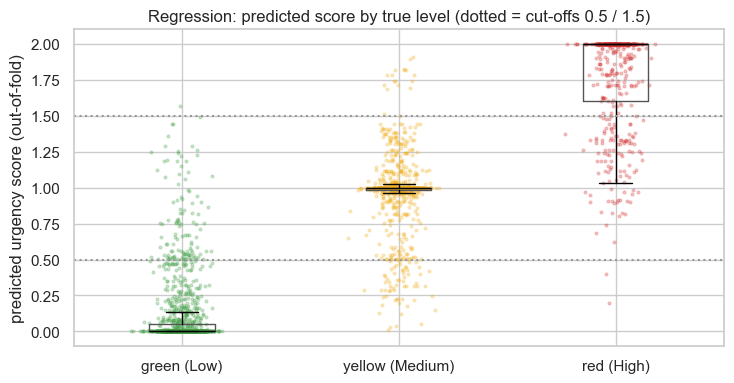

In [25]:
def cv_regress(reg_name, fs, data=None, repeats=N_REPEATS, seed0=SEED, cuts=(0.5, 1.5)):
    data = dev if data is None else data
    nums, cats = FEATURE_SETS[fs]; X, y, g = data[nums + cats], data["y"].to_numpy(), data["Diagnosis"].to_numpy()
    rows, first = [], None
    for r in range(repeats):
        yhat = np.zeros(len(data))
        for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=seed0 + r).split(X, y, g):
            est = Ridge(alpha=1.0) if reg_name == "Ridge regression" else RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED)
            pipe = Pipeline([("pre", make_pre(nums, cats, scale=(reg_name == "Ridge regression"))), ("m", est)]).fit(X.iloc[tr], y[tr])
            yhat[va] = pipe.predict(X.iloc[va])
        yh = np.clip(yhat, 0, 2); m = level_metrics(y, np.digitize(yh, cuts)); m.update({"MAE": mean_absolute_error(y, yh), "R2": r2_score(y, yh)}); rows.append(m)
        if r == 0: first = yh
    R = pd.DataFrame(rows)
    return {"model": reg_name, "features": fs, **{k: R[k].mean() for k in R}, **{k + "_sd": R[k].std(ddof=0) for k in R}}, first

REG, YHAT = [], {}
for rn in ["Ridge regression", "RF regressor"]:
    r_, yh_ = cv_regress(rn, BEST_FS); REG.append(r_); YHAT[rn] = yh_
reg_tab = pd.DataFrame(REG)
cls_row = BEST.to_dict(); cls_row["model"] = BEST_MODEL + " (classifier)"
cmp_ = pd.concat([reg_tab, pd.DataFrame([cls_row])], ignore_index=True)[["model", "features", "MAE", "R2", "macro_f1", "recall_high", "under_triage", "over_triage", "accuracy"]]
display(cmp_.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.boxplot([YHAT["RF regressor"][y_dev == k] for k in range(3)], showfliers=False, medianprops=dict(color="black"), boxprops=dict(color="#555"))
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["green (Low)", "yellow (Medium)", "red (High)"])
for k in range(3): ax.scatter(np.random.default_rng(0).normal(k + 1, .06, (y_dev == k).sum()), YHAT["RF regressor"][y_dev == k], s=4, alpha=.25, color=list(LEVEL_COL.values())[k])
ax.axhline(.5, color="#999", ls=":"); ax.axhline(1.5, color="#999", ls=":"); ax.set_ylabel("predicted urgency score (out-of-fold)"); ax.set_title("Regression: predicted score by true level (dotted = cut-offs 0.5 / 1.5)")
plt.tight_layout(); plt.show()

### 4.4.14 Why does the model work? Which columns matter, which are irrelevant?
Two complementary views on the **full triage-time feature set (FS3)** with the tuned forest, because single measures mislead when columns repeat each other (the slides' warning about correlated inputs):

1. **Grouped permutation importance** – on held-out diagnoses, shuffle all columns of a group *together* and measure the drop in macro-F1 and red recall (groups = columns that encode the same information, e.g. collapse symptom + collapse hours).
2. **Leave-one-group-out retraining** – retrain without the group (group-wise CV) and measure the loss. This is robust to redundancy: if another column repeats the information, the loss is small.

Hold-out baseline inside development set: macro-F1 0.889, red recall 0.914   (7 s)
Leave-one-group-out baseline: macro-F1 0.890, red recall 0.925   (13 s)


,PI_macroF1_drop,PI_se,PI_redrecall_drop,LOGO_macroF1_drop,LOGO_redrecall_drop,AMI (max in group),impact,verdict
DiscomfortLevel,0.270,0.003,0.171,0.130,-0.002,0.404,0.270,significant
"Collapse information (CollapseSymptom, RiskOfCollapse*)",0.228,0.005,0.553,-0.000,0.004,0.274,0.228,significant
"Examinations (Examination, Examination_2)",0.049,0.002,0.112,0.028,-0.004,0.046,0.049,significant
Avdeling (department),0.027,0.003,0.064,0.024,0.031,0.035,0.027,significant
Probability of critical outcome,0.024,0.001,0.095,0.019,0.006,0.044,0.024,significant
red_flag_score (combined),0.003,0.001,0.003,0.002,0.002,0.272,0.003,irrelevant given the others
Common/uncommon,0.002,0.001,0.004,0.001,0.004,0.005,0.002,irrelevant given the others
Interview reveal,0.002,0.001,0.025,-0.001,0.000,0.099,0.002,irrelevant given the others
ShameLevel,0.002,0.000,0.000,-0.000,0.000,0.057,0.002,irrelevant given the others
WalkSpeedModifier,0.001,0.000,0.000,-0.003,-0.002,0.028,0.001,irrelevant given the others


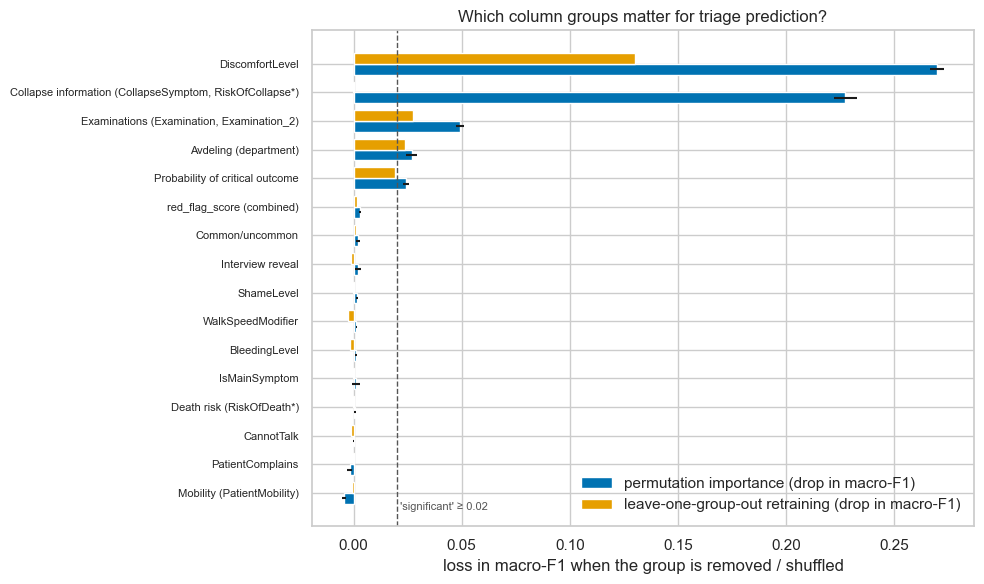

In [26]:
FS3N = "FS3 + archive knowledge"; f3_nums, f3_cats = FEATURE_SETS[FS3N]; f3_cols = f3_nums + f3_cats
GROUPS = {
 "DiscomfortLevel": ["discomfort"],
 "Collapse information (CollapseSymptom, RiskOfCollapse*)": ["collapse_symptom", "has_collapse", "collapse_start", "collapse_end", "collapse_window"],
 "Death risk (RiskOfDeath*)": ["death_start", "death_end", "has_death_risk"],
 "Mobility (PatientMobility)": ["mobility", "immobile"],
 "red_flag_score (combined)": ["red_flag_score"],
 "CannotTalk": ["cannot_talk"], "BleedingLevel": ["bleeding"],
 "Probability of critical outcome": ["p_crit"], "Avdeling (department)": ["avdeling"], "Common/uncommon": ["common"],
 "Examinations (Examination, Examination_2)": ["n_exam", "exam_level"],
 "Interview reveal": ["interview"], "IsMainSymptom": ["is_main"], "PatientComplains": ["complains"], "ShameLevel": ["shame"], "WalkSpeedModifier": ["walk_mod"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(f3_cols), set(f3_cols) ^ set(sum(GROUPS.values(), []))

# (1) grouped permutation importance on held-out diagnoses (inside the development set)
t0 = time.time(); rng = np.random.default_rng(SEED); pi_rows = {g_: [] for g_ in GROUPS}; base_f1, base_rc = [], []
Xd, yd, gd = dev[f3_cols], dev.y.to_numpy(), dev.Diagnosis.to_numpy()
for tr, va in GroupShuffleSplit(n_splits=3, test_size=0.25, random_state=SEED).split(Xd, yd, gd):
    pipe = Pipeline([("pre", make_pre(f3_nums, f3_cats)), ("m", make_model("Random forest (tuned)"))]).fit(Xd.iloc[tr], yd[tr])
    Xv, yv = Xd.iloc[va], yd[va]; pv = pipe.predict(Xv)
    f0, r0 = f1_score(yv, pv, average="macro"), recall_score(yv, pv, labels=[2], average=None)[0]; base_f1.append(f0); base_rc.append(r0)
    for g_, cols_ in GROUPS.items():
        for _ in range(8):
            Xp = Xv.copy(); perm = rng.permutation(len(Xv)); Xp[cols_] = Xv[cols_].to_numpy()[perm]
            pp = pipe.predict(Xp); pi_rows[g_].append((f0 - f1_score(yv, pp, average="macro"), r0 - recall_score(yv, pp, labels=[2], average=None)[0]))
PI = pd.DataFrame({g_: {"PI_macroF1_drop": np.mean([a for a, _ in v]), "PI_se": np.std([a for a, _ in v]) / np.sqrt(len(v)), "PI_redrecall_drop": np.mean([b for _, b in v])} for g_, v in pi_rows.items()}).T
print(f"Hold-out baseline inside development set: macro-F1 {np.mean(base_f1):.3f}, red recall {np.mean(base_rc):.3f}   ({time.time() - t0:.0f} s)")

# (2) leave-one-group-out retraining (one repeat, own seeds)
t0 = time.time()
base_r, _ = cv_classify("Random forest (tuned)", FS3N, repeats=1, seed0=SEED + 200)
logo = {}
for g_, cols_ in GROUPS.items():
    nn = [c for c in f3_nums if c not in cols_]; cc = [c for c in f3_cats if c not in cols_]
    r_, _ = cv_classify("Random forest (tuned)", (nn, cc), repeats=1, seed0=SEED + 200)
    logo[g_] = {"LOGO_macroF1_drop": base_r["macro_f1"] - r_["macro_f1"], "LOGO_redrecall_drop": base_r["recall_high"] - r_["recall_high"]}
LOGO = pd.DataFrame(logo).T
print(f"Leave-one-group-out baseline: macro-F1 {base_r['macro_f1']:.3f}, red recall {base_r['recall_high']:.3f}   ({time.time() - t0:.0f} s)")

ami_by_col = screen.set_index("col").AMI
IMP = PI.join(LOGO)
IMP["AMI (max in group)"] = [max(ami_by_col.get(c, 0) for c in cols_) for cols_ in GROUPS.values()]
IMP["impact"] = IMP[["PI_macroF1_drop", "LOGO_macroF1_drop"]].max(axis=1)
IMP["verdict"] = np.where(IMP.impact >= 0.02, "significant", np.where(IMP.impact >= 0.005, "minor", "irrelevant given the others"))
IMP = IMP.sort_values("impact", ascending=False)
display(IMP.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
Y = np.arange(len(IMP)); h = 0.38
ax.barh(Y + h / 2, IMP.PI_macroF1_drop, h, xerr=IMP.PI_se, color="#0072B2", label="permutation importance (drop in macro-F1)")
ax.barh(Y - h / 2, IMP.LOGO_macroF1_drop, h, color="#E69F00", label="leave-one-group-out retraining (drop in macro-F1)")
ax.set_yticks(Y); ax.set_yticklabels(IMP.index, fontsize=8); ax.invert_yaxis(); ax.axvline(0.02, color="#555", ls="--", lw=1); ax.text(0.02, len(IMP) - .4, " 'significant' ≥ 0.02", fontsize=8, color="#555")
ax.set_xlabel("loss in macro-F1 when the group is removed / shuffled"); ax.set_title("Which column groups matter for triage prediction?"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

In [27]:
# Final answer to "important / irrelevant columns" for ALL 49 columns
RAW2GROUP = {"DiscomfortLevel": "DiscomfortLevel", "PatientMobility": "Mobility (PatientMobility)", "CollapseSymptom": "Collapse information (CollapseSymptom, RiskOfCollapse*)",
             "RiskOfCollapseStartHours": "Collapse information (CollapseSymptom, RiskOfCollapse*)", "RiskOfCollapseEndHours": "Collapse information (CollapseSymptom, RiskOfCollapse*)",
             "RiskOfDeathStartHours": "Death risk (RiskOfDeath*)", "RiskOfDeathEndHours": "Death risk (RiskOfDeath*)", "CannotTalk": "CannotTalk", "BleedingLevel": "BleedingLevel",
             P_COL: "Probability of critical outcome", "Avdeling": "Avdeling (department)", "Common/uncommon": "Common/uncommon",
             "Examination": "Examinations (Examination, Examination_2)", "Examination_2": "Examinations (Examination, Examination_2)", "Interview reveal": "Interview reveal",
             "IsMainSymptom": "IsMainSymptom", "PatientComplains": "PatientComplains", "ShameLevel": "ShameLevel", "WalkSpeedModifier": "WalkSpeedModifier"}
rf_all = RES[RES.model == "Random forest (tuned)"].set_index("features")
fs4_gain = rf_all.loc["FS4 + treatment-side (not known at triage)", "macro_f1"] - rf_all.loc[FS3N, "macro_f1"]
verd = []
for i, c in enumerate(raw.columns, 1):
    role = INFO[c][2]
    if c in RAW2GROUP:
        g_ = RAW2GROUP[c]; v = IMP.loc[g_, "verdict"]; ev = f"impact {IMP.loc[g_, 'impact']:.3f}, AMI {IMP.loc[g_, 'AMI (max in group)']:.3f}"
        if v == "irrelevant given the others" and g_ in ("Collapse information (CollapseSymptom, RiskOfCollapse*)", "Mobility (PatientMobility)", "Death risk (RiskOfDeath*)"): v = v + " (redundant with other columns)"
    elif role == "TARGET": v, ev = "target", "triage level"
    elif role == "PROXY": v, ev = "excluded: leakage", INFO[c][3]
    elif role == "TREAT": v, ev = "informative, but NOT available at triage", f"adds {fs4_gain:+.3f} macro-F1 as a block (FS4)"
    elif role == "ID": v, ev = "key (not a feature)", INFO[c][3]
    else: v, ev = "irrelevant / redundant", INFO[c][3]
    verd.append((i, c[:46], INFO[c][0], role, v, ev))
final_verdict = pd.DataFrame(verd, columns=["no", "column", "group", "role", "verdict", "evidence / reason"])
final_verdict.to_csv(f"{OUT_DIR}/final_column_verdict.csv", index=False)
IMP.round(4).to_csv(f"{OUT_DIR}/feature_importance.csv")
display(final_verdict)
print(final_verdict.verdict.value_counts().to_string())

,no,column,group,role,verdict,evidence / reason
0,1,Diagnosis,Key,ID,key (not a feature),Group key for splitting and patient generation; not a feature (the...
1,2,Symptom,Key,ID,key (not a feature),Used to describe patients; 611 levels with ~6 rows each would be m...
2,3,Examination,Examination,ARCH,significant,"impact 0.049, AMI 0.046"
3,4,Examination_2,Examination,ARCH,significant,"impact 0.049, AMI 0.046"
4,5,Behandlding,Treatment,TREAT,"informative, but NOT available at triage",adds +0.031 macro-F1 as a block (FS4)
5,6,Avdeling,Archive knowledge,ARCH,significant,"impact 0.027, AMI 0.035"
6,7,Common/uncommon,Archive knowledge,ARCH,irrelevant given the others,"impact 0.002, AMI 0.005"
7,8,"Sannsynlighet for kritisk utfall, når symptom",Archive knowledge,ARCH,significant,"impact 0.024, AMI 0.044"
8,9,Kritiskhet kategori,Label,TARGET,target,triage level
9,10,Interview reveal,Observable,OBS,irrelevant given the others,"impact 0.002, AMI 0.099"


verdict
irrelevant / redundant                                        22
significant                                                    8
irrelevant given the others                                    8
informative, but NOT available at triage                       4
irrelevant given the others (redundant with other columns)     3
key (not a feature)                                            2
target                                                         1
excluded: leakage                                              1


**Reading the table.** Single columns that repeat one another (collapse symptom, collapse start/end, `has_collapse`, mobility, `immobile`) share their information; the group view prevents the redundancy from hiding their value. `red_flag_score` is a *combination* of other columns, so its extra value is small once its components are present, but it is the one-number, explainable summary a triage nurse can use at the bedside (§3.3.1).

### 4.4.6–4.4.9 Plausibility, rules and knowledge-base check
A shallow decision tree gives a **verbal description** of the learned logic (lecture 4.4.12). A plausible triage logic would flag immobility, collapse/shock, inability to talk and bleeding as urgent, and low discomfort without red flags as non-urgent.

In [28]:
pre_t = make_pre(f3_nums, f3_cats); Xt = pre_t.fit_transform(dev[f3_cols])
names_t = [n.replace("num__", "").replace("cat__", "") for n in pre_t.get_feature_names_out()]
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=25, class_weight="balanced", random_state=SEED).fit(Xt, dev.y)
print("Shallow tree (class 0 = Low/green, 1 = Medium/yellow, 2 = High/red), trained on the development set:\n")
print(export_text(tree, feature_names=names_t))
print(f"Accuracy of this 8-leaf tree on the development set: {tree.score(Xt, dev.y):.3f}  (the forest is more accurate but not readable)")

Shallow tree (class 0 = Low/green, 1 = Medium/yellow, 2 = High/red), trained on the development set:

|--- discomfort_Low <= 0.50
|   |--- discomfort_Medium <= 0.50
|   |   |--- red_flag_score <= 0.50
|   |   |   |--- class: 1
|   |   |--- red_flag_score >  0.50
|   |   |   |--- class: 2
|   |--- discomfort_Medium >  0.50
|   |   |--- shame <= 2.50
|   |   |   |--- class: 1
|   |   |--- shame >  2.50
|   |   |   |--- class: 1
|--- discomfort_Low >  0.50
|   |--- collapse_symptom_None <= 0.50
|   |   |--- class: 2
|   |--- collapse_symptom_None >  0.50
|   |   |--- walk_mod <= 0.25
|   |   |   |--- class: 0
|   |   |--- walk_mod >  0.25
|   |   |   |--- class: 0

Accuracy of this 8-leaf tree on the development set: 0.790  (the forest is more accurate but not readable)


### 4.4.10 Check the reliability of the result
Rows of one diagnosis are strongly correlated, so naive confidence intervals over rows would be too narrow. We use a **cluster bootstrap over diagnoses** (500 resamples of whole diagnoses) on the out-of-fold predictions.

In [29]:
def cluster_bootstrap(y, pred, groups, n=500, seed=SEED):
    rng = np.random.default_rng(seed); idx_by = pd.Series(np.arange(len(y))).groupby(groups).apply(lambda s: s.to_numpy()); keys = idx_by.index.to_numpy()
    out = []
    for _ in range(n):
        ii = np.concatenate([idx_by[k] for k in rng.choice(keys, size=len(keys), replace=True)]); m = level_metrics(y[ii], pred[ii]); out.append((m["macro_f1"], m["recall_high"], m["under_triage"], m["over_triage"]))
    a = np.array(out); lo, hi = np.percentile(a, [2.5, 97.5], axis=0)
    return pd.DataFrame({"estimate": level_metrics(y, pred)["macro_f1"], "ci_low": lo, "ci_high": hi}, index=["macro_f1", "recall_high", "under_triage", "over_triage"]).assign(
        estimate=[level_metrics(y, pred)[k] for k in ["macro_f1", "recall_high", "under_triage", "over_triage"]])
ci_dev = cluster_bootstrap(y_dev, pred_dev, dev.Diagnosis.to_numpy())
display(ci_dev.round(3))
print("Repeat-to-repeat sd of the CV estimate is tiny (see tables above); the uncertainty that matters is the variation between diagnoses, shown by the 95 % intervals here.")

,estimate,ci_low,ci_high
macro_f1,0.886,0.870,0.899
recall_high,0.925,0.897,0.947
under_triage,0.031,0.025,0.037
over_triage,0.071,0.061,0.081


Repeat-to-repeat sd of the CV estimate is tiny (see tables above); the uncertainty that matters is the variation between diagnoses, shown by the 95 % intervals here.


# 5. Evaluation (CRISP-DM phase 5)
CRISP-DM task **5.1 Evaluate results** is implemented in §5.1–5.7: the one-time hold-out test (§5.1), the random patient list (§5.2), sensitivity (§5.3), Six Sigma (§5.4), scenario analysis (§5.5), the cost-sensitive decision rule (§5.6) and a Lean waiting-time simulation (§5.7). Task **5.2 Review process** is §5.8 and **5.3 Determine next steps** is §5.9. As the lecture says, *results = models + findings*: findings (leakage, structural missingness, hidden urgency) count as much as the model.

## 5.1 Evaluate results – hold-out test and success criteria
The test set (70 diagnoses never used for development) is used **once** for the selected configuration. Other configurations are shown for comparison only – they were *not* selected on it.

In [30]:
y_test = test.y.to_numpy(); cols_final = FINAL_NUMS + FINAL_CATS
def fit_pipe(model_name, nums, cats, data):
    return Pipeline([("pre", make_pre(nums, cats, scale=(model_name == "Logistic regression"))), ("m", make_model(model_name))]).fit(data[nums + cats], data["y"])

pipe_final_dev = fit_pipe(BEST_MODEL, FINAL_NUMS, FINAL_CATS, dev)
proba_test = pipe_final_dev.predict_proba(test[cols_final]); pred_test = proba_test.argmax(1)
def rule_redflag(frame): return np.where(frame["red_flag_score"].to_numpy() >= 1, 2, 0)      # nurse checklist: any red flag -> red, else green

rows = []
def add_row(name, pred, proba=None, note=""):
    m = level_metrics(y_test, pred); ci = cluster_bootstrap(y_test, pred, test.Diagnosis.to_numpy(), n=300)
    rows.append({"configuration": name, "macro_f1": m["macro_f1"], "macro_f1 95% CI": f"[{ci.loc['macro_f1', 'ci_low']:.2f}, {ci.loc['macro_f1', 'ci_high']:.2f}]",
                 "red_recall": m["recall_high"], "red_recall 95% CI": f"[{ci.loc['recall_high', 'ci_low']:.2f}, {ci.loc['recall_high', 'ci_high']:.2f}]",
                 "under_triage": m["under_triage"], "over_triage": m["over_triage"], "accuracy": m["accuracy"],
                 "roc_auc": roc_auc_score(y_test, proba, multi_class="ovr") if proba is not None else np.nan, "note": note})
add_row("Majority-class baseline", np.zeros(len(test), int), note="reference")
add_row("Red-flag rule (score>=1 -> red, else green)", rule_redflag(test), note="transparent rule (Health01-style)")
add_row(f"SELECTED: {BEST_MODEL} / {BEST_FS}", pred_test, proba_test, note="selected in §4.4")
ALT = [("Random forest (tuned)", "FS1 bedside observations", "no DiscomfortLevel, no archive"), ("Random forest (tuned)", FS3B, "no DiscomfortLevel"),
       ("Random forest (tuned)", "FS3 + archive knowledge", "with DiscomfortLevel"), ("Random forest (tuned)", "FS4 + treatment-side (not known at triage)", "upper bound; violates C3")]
for m_, fs_, note_ in ALT:
    if (m_, fs_) == (BEST_MODEL, BEST_FS): continue
    n_, c_ = FEATURE_SETS[fs_]; p_ = fit_pipe(m_, n_, c_, dev); pr_ = p_.predict_proba(test[n_ + c_]); add_row(f"{m_} / {fs_.split(' ')[0]}", pr_.argmax(1), pr_, note_)
T_test = pd.DataFrame(rows); display(T_test.round(3))

m_fin = level_metrics(y_test, pred_test); ci_fin = cluster_bootstrap(y_test, pred_test, test.Diagnosis.to_numpy(), n=500)
crit_tab = pd.DataFrame([
 ("C1  red recall >= 0.90", m_fin["recall_high"], f"[{ci_fin.loc['recall_high', 'ci_low']:.3f}, {ci_fin.loc['recall_high', 'ci_high']:.3f}]", "met" if m_fin["recall_high"] >= .90 else "NOT met", ci_fin.loc['recall_high', 'ci_low'] >= .90),
 ("C2  macro-F1 >= 0.80",   m_fin["macro_f1"],    f"[{ci_fin.loc['macro_f1', 'ci_low']:.3f}, {ci_fin.loc['macro_f1', 'ci_high']:.3f}]",    "met" if m_fin["macro_f1"] >= .80 else "NOT met",    ci_fin.loc['macro_f1', 'ci_low'] >= .80),
 ("C3  only features known at triage", np.nan, "-", "met" if not BEST_FS.startswith("FS4") else "NOT met", True)],
 columns=["criterion", "value (hold-out)", "95% CI (diagnosis bootstrap)", "verdict (point estimate)", "lower CI bound also passes?"])
display(crit_tab.round(3))
print("Selected configuration uses DiscomfortLevel:", bool(BEST.uses_DiscomfortLevel))

,configuration,macro_f1,macro_f1 95% CI,red_recall,red_recall 95% CI,under_triage,over_triage,accuracy,roc_auc,note
0,Majority-class baseline,0.216,"[0.20, 0.23]",0.000,"[0.00, 0.00]",0.522,0.000,0.478,NaN,reference
1,"Red-flag rule (score>=1 -> red, else green)",0.501,"[0.47, 0.53]",0.692,"[0.60, 0.78]",0.401,0.007,0.592,NaN,transparent rule (Health01-style)
2,SELECTED: Random forest (tuned) / FS3 + archive knowledge,0.897,"[0.87, 0.92]",0.967,"[0.93, 0.99]",0.023,0.068,0.908,0.990,selected in §4.4
3,Random forest (tuned) / FS1,0.650,"[0.61, 0.68]",0.942,"[0.88, 0.98]",0.121,0.238,0.641,0.828,"no DiscomfortLevel, no archive"
4,Random forest (tuned) / FS3b,0.753,"[0.72, 0.79]",0.967,"[0.93, 0.99]",0.112,0.151,0.737,0.891,no DiscomfortLevel
5,Random forest (tuned) / FS4,0.924,"[0.89, 0.95]",0.992,"[0.97, 1.00]",0.012,0.052,0.936,0.995,upper bound; violates C3


,criterion,value (hold-out),95% CI (diagnosis bootstrap),verdict (point estimate),lower CI bound also passes?
0,C1 red recall >= 0.90,0.967,"[0.933, 0.993]",met,True
1,C2 macro-F1 >= 0.80,0.897,"[0.869, 0.922]",met,True
2,C3 only features known at triage,NaN,-,met,True


Selected configuration uses DiscomfortLevel: True


## 5.2 Interpret the results in terms of the application – the random patient list
The model works on *symptoms*, a triage nurse works on *patients*. We generate **3,000 random patients** (§3.4), predict every presented symptom with a model that **never saw that diagnosis** (out-of-fold predictions for development diagnoses, the hold-out model for test diagnoses) and give the patient the **most urgent predicted level**. Ground truth is the most urgent level among the presented symptoms.

,patients,red patients,red recall,under-triage,over-triage,accuracy,macro-F1
model | all patients,3000.0,490.0,0.898,0.027,0.051,0.922,0.897
model | development diagnoses (out-of-fold),2398.0,367.0,0.875,0.030,0.055,0.915,0.888
model | test diagnoses (hold-out),602.0,123.0,0.967,0.017,0.037,0.947,0.927
red-flag rule | all patients,3000.0,490.0,0.735,0.701,0.017,0.281,0.371
red-flag rule | development diagnoses (out-of-fold),2398.0,367.0,0.725,0.701,0.020,0.280,0.369
red-flag rule | test diagnoses (hold-out),602.0,123.0,0.764,0.704,0.008,0.287,0.373


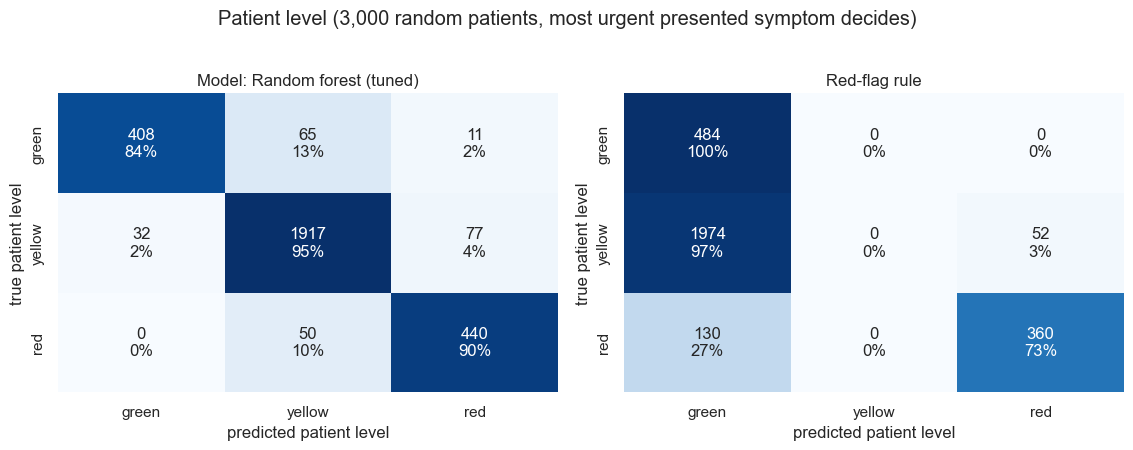

Distinct diagnoses among the 3,000 patients: 349 | patients from test diagnoses: 602
Hidden urgency: for 47.2% of the patients the diagnosis contains a more urgent finding than the (up to 3) symptoms revealed in the interview.
Under-triage rate measured against the FULL diagnosis urgency: model 46.8%, vs 2.7% against the presented symptoms.
-> A symptom-based model cannot remove this gap: reassessment as more symptoms appear is part of the deployment plan (§6).


In [31]:
PROBA_ROW = np.zeros((len(df), 3)); PROBA_ROW[dev_pos] = OOF[(BEST_MODEL, BEST_FS)]; PROBA_ROW[test_pos] = proba_test
PRED_ROW, RULE_ROW = PROBA_ROW.argmax(1), rule_redflag(df)
test_dx = set(test.Diagnosis)

PT = generate_patients(3000, seed=SEED + 7)
patient_max = lambda P, row_vec: P.presented_rows.map(lambda r: int(np.max(row_vec[r])))
PT["pred_model"], PT["pred_rule"] = patient_max(PT, PRED_ROW), patient_max(PT, RULE_ROW)
PT["maxP_high"] = PT.presented_rows.map(lambda r: float(PROBA_ROW[r, 2].max()))
PT["in_test"] = PT.Diagnosis.isin(test_dx)

def pt_metrics(P, col, truth="true_level"):
    t, p = P[truth].to_numpy(), P[col].to_numpy(); red = t == 2
    return {"patients": len(P), "red patients": int(red.sum()), "red recall": float((p[red] == 2).mean()) if red.any() else np.nan, "under-triage": float((p < t).mean()),
            "over-triage": float((p > t).mean()), "accuracy": float((p == t).mean()), "macro-F1": f1_score(t, p, average="macro")}
tab = pd.DataFrame({f"{who} | {sub}": pt_metrics(P_, c_) for who, c_ in [("model", "pred_model"), ("red-flag rule", "pred_rule")]
                    for sub, P_ in [("all patients", PT), ("development diagnoses (out-of-fold)", PT[~PT.in_test]), ("test diagnoses (hold-out)", PT[PT.in_test])]}).T
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
for a_, (col, ttl) in zip(ax, [("pred_model", f"Model: {BEST_MODEL}"), ("pred_rule", "Red-flag rule")]):
    c_ = confusion_matrix(PT.true_level, PT[col], labels=[0, 1, 2])
    sns.heatmap(c_ / c_.sum(1, keepdims=True), annot=np.array([[f"{c_[i, j]}\n{c_[i, j] / c_[i].sum():.0%}" for j in range(3)] for i in range(3)]), fmt="", cmap="Blues", cbar=False, ax=a_,
                xticklabels=["green", "yellow", "red"], yticklabels=["green", "yellow", "red"]); a_.set_xlabel("predicted patient level"); a_.set_ylabel("true patient level"); a_.set_title(ttl)
plt.suptitle("Patient level (3,000 random patients, most urgent presented symptom decides)", y=1.02); plt.tight_layout(); plt.show()

hidden = (PT.true_level_full > PT.true_level)
print(f"Distinct diagnoses among the 3,000 patients: {PT.Diagnosis.nunique()} | patients from test diagnoses: {PT.in_test.sum()}")
print(f"Hidden urgency: for {hidden.mean():.1%} of the patients the diagnosis contains a more urgent finding than the (up to 3) symptoms revealed in the interview.")
print(f"Under-triage rate measured against the FULL diagnosis urgency: model {(PT.pred_model < PT.true_level_full).mean():.1%}, vs {(PT.pred_model < PT.true_level).mean():.1%} against the presented symptoms.")
print("-> A symptom-based model cannot remove this gap: reassessment as more symptoms appear is part of the deployment plan (§6).")

## 5.3 Sensitivity analysis – does the result depend on the split?
The selected configuration is retrained and tested on **five different, disjoint sets of unseen diagnoses** (group-wise 5-fold over the whole archive), instead of the single hold-out set.

In [32]:
rows = []
for k, (tr, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + 77).split(df, df.y, df.Diagnosis), 1):
    p_ = fit_pipe(BEST_MODEL, FINAL_NUMS, FINAL_CATS, df.iloc[tr]); pr_ = p_.predict(df.iloc[va][cols_final]); m_ = level_metrics(df.y.to_numpy()[va], pr_)
    rows.append({"fold": k, "test diagnoses": df.iloc[va].Diagnosis.nunique(), **{k_: m_[k_] for k_ in ["macro_f1", "recall_high", "under_triage", "over_triage", "accuracy"]}})
SENS = pd.DataFrame(rows); display(SENS.round(3))
print(f"mean ± sd over 5 splits:  macro-F1 {SENS.macro_f1.mean():.3f} ± {SENS.macro_f1.std():.3f} | red recall {SENS.recall_high.mean():.3f} ± {SENS.recall_high.std():.3f} "
      f"| worst fold red recall {SENS.recall_high.min():.3f}")
print("C1 (red recall >= 0.90) holds in", int((SENS.recall_high >= .9).sum()), "of 5 splits;  C2 (macro-F1 >= 0.80) holds in", int((SENS.macro_f1 >= .8).sum()), "of 5 splits.")
print(f"Caution: the single hold-out set of §5.1 gives red recall {m_fin['recall_high']:.3f}, the mean over five splits is {SENS.recall_high.mean():.3f} (range {SENS.recall_high.min():.3f}-{SENS.recall_high.max():.3f}); "
      f"development CV gave {BEST.recall_high:.3f}.")
print("-> Report the multi-split figure. C1 is met on average but not in every split; this is the motivation for the cost-sensitive rule in §5.6, which trades extra over-triage for fewer missed red patients.")

,fold,test diagnoses,macro_f1,recall_high,under_triage,over_triage,accuracy
0,1,70,0.898,0.917,0.031,0.060,0.909
1,2,67,0.886,0.908,0.033,0.072,0.896
2,3,72,0.892,0.916,0.023,0.073,0.904
3,4,66,0.906,0.958,0.026,0.059,0.916
4,5,74,0.883,0.926,0.032,0.070,0.897


mean ± sd over 5 splits:  macro-F1 0.893 ± 0.009 | red recall 0.925 ± 0.020 | worst fold red recall 0.908
C1 (red recall >= 0.90) holds in 5 of 5 splits;  C2 (macro-F1 >= 0.80) holds in 5 of 5 splits.
Caution: the single hold-out set of §5.1 gives red recall 0.967, the mean over five splits is 0.925 (range 0.908-0.958); development CV gave 0.919.
-> Report the multi-split figure. C1 is met on average but not in every split; this is the motivation for the cost-sensitive rule in §5.6, which trades extra over-triage for fewer missed red patients.


## 5.4 Six Sigma – defects, DPMO and sigma level
**DMAIC mapping:** *Define* the defect = a **red patient triaged below red** (under-triage of a critical patient); *Measure* DPMO = defects per million opportunities, with one opportunity per truly red patient; *Analyse* where defects arise (§5.5, §4.4); *Improve* by moving the decision rule (§5.6); *Control* by monitoring (§6.2). Sigma level = `Φ⁻¹(1 − DPMO/10⁶) + 1.5` (conventional 1.5σ shift). Confidence intervals: bootstrap over diagnoses.

In [33]:
def sigma_from(defects, opps):
    dpmo = 1e6 * defects / opps
    return dpmo, (min(6.0, norm.ppf(1 - dpmo / 1e6) + 1.5) if dpmo > 0 else 6.0)

def six_sigma(P, col, n_boot=400, seed=SEED):
    red = P.true_level.to_numpy() == 2; miss = red & (P[col].to_numpy() < 2)
    d, s = sigma_from(miss.sum(), red.sum())
    idx_by = pd.Series(np.arange(len(P))).groupby(P.Diagnosis.to_numpy()).apply(lambda x: x.to_numpy()); keys = idx_by.index.to_numpy(); rng = np.random.default_rng(seed); sg = []
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[k] for k in rng.choice(keys, len(keys), replace=True)])
        if red[ii].sum() > 0: sg.append(sigma_from(miss[ii].sum(), red[ii].sum())[1])
    lo, hi = np.percentile(sg, [2.5, 97.5])
    any_def = (P[col].to_numpy() < P.true_level.to_numpy()).mean()
    return {"opportunities (red patients)": int(red.sum()), "defects (red triaged lower)": int(miss.sum()), "DPMO": round(d), "sigma level": round(s, 2), "sigma 95% CI": f"[{lo:.2f}, {hi:.2f}]",
            "any under-triage (all patients)": f"{any_def:.1%}"}
SS = pd.DataFrame({"model (argmax)": six_sigma(PT, "pred_model"), "red-flag rule": six_sigma(PT, "pred_rule")}).T
display(SS)
print("Reading: a sigma level around 3 corresponds to ~67,000 DPMO; 6 sigma = 3.4 DPMO. The sigma level is only an illustration here: it describes the archive-based patient sample, not a hospital.")

,opportunities (red patients),defects (red triaged lower),DPMO,sigma level,sigma 95% CI,any under-triage (all patients)
model (argmax),490,50,102041,2.77,"[2.47, 3.17]",2.7%
red-flag rule,490,130,265306,2.13,"[1.86, 2.41]",70.1%


Reading: a sigma level around 3 corresponds to ~67,000 DPMO; 6 sigma = 3.4 DPMO. The sigma level is only an illustration here: it describes the archive-based patient sample, not a hospital.


## 5.5 Scenario analysis – where does the model fail?
Out-of-fold / hold-out predictions (always for unseen diagnoses) split by situation. Small groups are flagged with their *n*; differences between small groups should not be over-interpreted.

,avdeling,rows,share red,red recall,under-triage,over-triage,accuracy
3,infectious,716,0.154,0.891,0.032,0.073,0.895
4,internal medicine,672,0.135,0.912,0.037,0.079,0.884
5,neurology,314,0.150,0.936,0.041,0.057,0.901
7,trauma,533,0.392,0.938,0.026,0.116,0.857
2,general medicine,479,0.111,0.943,0.029,0.065,0.906
0,cardiology,267,0.243,0.985,0.007,0.011,0.981
6,ortho,441,0.054,1.000,0.032,0.059,0.909
1,emergency,251,0.000,NaN,0.008,0.060,0.932


,_block,rows,share red,red recall,under-triage,over-triage,accuracy
0,no simulator attributes (891-row block),888,0.249,0.837,0.060,0.242,0.698
1,with simulator attributes,2785,0.136,0.989,0.019,0.016,0.964



Patient level by number of revealed symptoms:


,patients,red patients,red recall,under-triage,over-triage
n,,,,,
1,155.0,48.0,0.771,0.110,0.000
2,9.0,0.0,0.000,0.000,0.000
3,2836.0,442.0,0.912,0.023,0.054


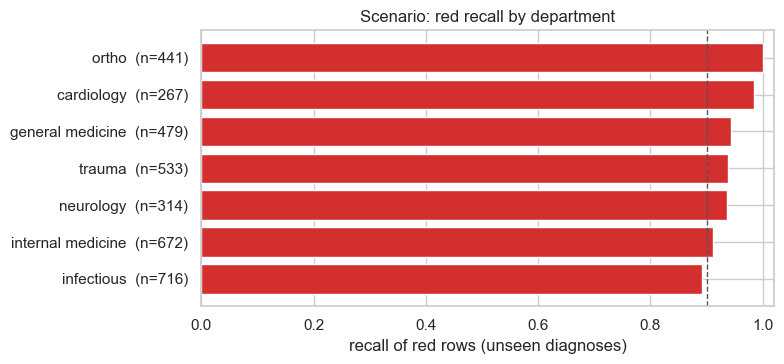

In [34]:
def by_group(frame, key):
    t, p = frame.y.to_numpy(), PRED_ROW[frame.index.to_numpy()]
    out = []
    for k, g_ in frame.groupby(key, dropna=False):
        ii = np.where(frame[key].eq(k).to_numpy() if not pd.isna(k) else frame[key].isna().to_numpy())[0]
        yy, pp = t[ii], p[ii]; red = yy == 2
        out.append({key: k, "rows": len(ii), "share red": red.mean(), "red recall": (pp[red] == 2).mean() if red.any() else np.nan, "under-triage": (pp < yy).mean(), "over-triage": (pp > yy).mean(), "accuracy": (pp == yy).mean()})
    return pd.DataFrame(out)
df["_block"] = np.where(df["Hazard"].isna(), "no simulator attributes (891-row block)", "with simulator attributes")
dept = by_group(df, "avdeling").sort_values("red recall"); blk = by_group(df, "_block")
display(dept.round(3)); display(blk.round(3))
pt_n = PT.assign(n=PT.n_symptoms).groupby("n").apply(lambda g_: pd.Series({"patients": len(g_), "red patients": int((g_.true_level == 2).sum()),
        "red recall": ((g_.pred_model == 2) & (g_.true_level == 2)).sum() / max(1, (g_.true_level == 2).sum()), "under-triage": (g_.pred_model < g_.true_level).mean(), "over-triage": (g_.pred_model > g_.true_level).mean()}))
print("\nPatient level by number of revealed symptoms:"); display(pt_n.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8)); d_ = dept.sort_values("red recall")
ax.barh(d_.avdeling + "  (n=" + d_.rows.astype(str) + ")", d_["red recall"], color="#d32f2f"); ax.axvline(.9, color="#555", ls="--", lw=1)
ax.set_xlim(0, 1.02); ax.set_xlabel("recall of red rows (unseen diagnoses)"); ax.set_title("Scenario: red recall by department"); plt.tight_layout(); plt.show()
df.drop(columns="_block", inplace=True)

## 5.6 Optimization technique – cost-sensitive decision rule
Triage errors have unequal costs. With a cost matrix `C[true, predicted]` where over-triage costs **1 per level** and under-triage costs **w per level**, the decision that minimises the *expected cost* for a patient with class probabilities `p` is  
`predict = argmin_j Σ_k p_k · C[k, j]` – a closed-form optimisation per patient. The forest's probabilities are not perfectly calibrated, so the weight `w'` used in the rule is **tuned on the development out-of-fold predictions** to minimise the realised cost at the clinically assumed ratio **w = 10** (an under-triaged level is ten times as bad as an over-triaged level – an assumption to be replaced by clinical judgement). The test set then gives an unbiased check.

red recall                               over-triage                                  macro-F1                          mean cost @ w=10                
set development (out-of-fold) test (hold-out) development (out-of-fold) test (hold-out) development (out-of-fold) test (hold-out) development (out-of-fold) test (hold-out)
w'                                                                                                                                                                         
1                       0.896           0.950                     0.073           0.066                     0.882           0.898                     0.413           0.345
2                       0.975           0.983                     0.104           0.101                     0.876           0.877                     0.220           0.204
3                       0.983           1.000                     0.125           0.127                     0.859           0.857                     0.203           0.179
5                       0.985           1.000                     0.156           0.153                     0.829           0.832                     0.231           0.201
8                       0.990           1.000                     0.185           0.178                     0.801           0.808                     0.252           0.219
10                      0.990           1.000                     0.193           0.195                     0.792           0.790                     0.265           0.240
15                      0.992           1.000                     0.214           0.223                     0.770           0.761                     0.286           0.279
25                      0.994           1.000                     0.240           0.233                     0.745           0.750                     0.309           0.297
50                      0.994           1.000                     0.260           0.241                     0.723           0.742                     0.350           0.312

Selected decision weight w' = 3 (minimises the development cost at w = 10).
Hold-out comparison:


,recall_high,under_triage,over_triage,macro_f1,mean cost @ w=10
argmax (plain),0.967,0.023,0.068,0.897,0.322
cost-sensitive (w'=3),1.000,0.003,0.127,0.857,0.179


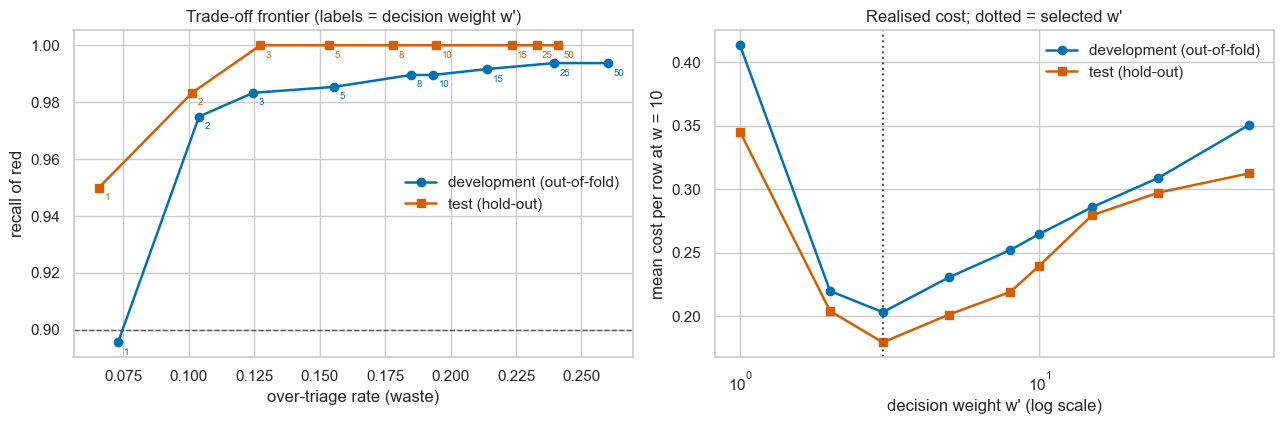


Patient level, cost-sensitive rule:


,patients,red patients,red recall,under-triage,over-triage,accuracy,macro-F1
argmax,3000.0,490.0,0.898,0.027,0.051,0.922,0.897
cost-sensitive w'=3,3000.0,490.0,0.990,0.005,0.093,0.903,0.880



Six Sigma 'Improve' step - defects and sigma level before / after moving the decision rule:


,opportunities (red patients),defects (red triaged lower),DPMO,sigma level,sigma 95% CI,any under-triage (all patients)
model (argmax),490,50,102041,2.77,"[2.47, 3.17]",2.7%
model (cost-sensitive w'=3),490,5,10204,3.82,"[3.47, 6.00]",0.5%


In [35]:
ASSUMED_W = 10
def cost_matrix(w):
    C = np.zeros((3, 3))
    for k in range(3):
        for j in range(3): C[k, j] = w * (k - j) if j < k else (j - k)
    return C
decide = lambda proba, w: (proba @ cost_matrix(w)).argmin(1)
realised_cost = lambda y, pred, w=ASSUMED_W: float(cost_matrix(w)[y, pred].mean())

W_GRID = [1, 2, 3, 5, 8, 10, 15, 25, 50]
proba_dev = OOF[(BEST_MODEL, BEST_FS)]
rows = []
for w in W_GRID:
    for who, y_, pr_ in [("development (out-of-fold)", y_dev, proba_dev), ("test (hold-out)", y_test, proba_test)]:
        pp = decide(pr_, w); m_ = level_metrics(y_, pp)
        rows.append({"w'": w, "set": who, "red recall": m_["recall_high"], "over-triage": m_["over_triage"], "under-triage": m_["under_triage"], "macro-F1": m_["macro_f1"], f"mean cost @ w={ASSUMED_W}": realised_cost(y_, pp)})
SW = pd.DataFrame(rows)
costcol = f"mean cost @ w={ASSUMED_W}"
W_STAR = int(SW[SW.set.str.startswith("dev")].sort_values([costcol, "w'"]).iloc[0]["w'"])
display(SW.pivot(index="w'", columns="set", values=["red recall", "over-triage", "macro-F1", costcol]).round(3))

base_t, star_t = level_metrics(y_test, proba_test.argmax(1)), level_metrics(y_test, decide(proba_test, W_STAR))
comp = pd.DataFrame({"argmax (plain)": {**{k: base_t[k] for k in ["recall_high", "under_triage", "over_triage", "macro_f1"]}, costcol: realised_cost(y_test, proba_test.argmax(1))},
                     f"cost-sensitive (w'={W_STAR})": {**{k: star_t[k] for k in ["recall_high", "under_triage", "over_triage", "macro_f1"]}, costcol: realised_cost(y_test, decide(proba_test, W_STAR))}}).T
print(f"Selected decision weight w' = {W_STAR} (minimises the development cost at w = {ASSUMED_W}).\nHold-out comparison:"); display(comp.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for who, col, mk in [("development (out-of-fold)", "#0072B2", "o"), ("test (hold-out)", "#D55E00", "s")]:
    s_ = SW[SW.set == who]; ax[0].plot(s_["over-triage"], s_["red recall"], marker=mk, color=col, label=who, lw=1.8)
    for _, r_ in s_.iterrows(): ax[0].annotate(f"{int(r_['w' + chr(39)])}", (r_["over-triage"], r_["red recall"]), textcoords="offset points", xytext=(4, -9), fontsize=7, color=col)
    ax[1].plot(s_["w'"], s_[costcol], marker=mk, color=col, label=who, lw=1.8)
ax[0].axhline(.9, color="#555", ls="--", lw=1); ax[0].set_xlabel("over-triage rate (waste)"); ax[0].set_ylabel("recall of red"); ax[0].set_title("Trade-off frontier (labels = decision weight w')"); ax[0].legend(frameon=False)
ax[1].set_xscale("log"); ax[1].axvline(W_STAR, color="#555", ls=":"); ax[1].set_xlabel("decision weight w' (log scale)"); ax[1].set_ylabel(f"mean cost per row at w = {ASSUMED_W}"); ax[1].set_title("Realised cost; dotted = selected w'"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

PRED_ROW_CS = decide(PROBA_ROW, W_STAR)
PT["pred_cs"] = patient_max(PT, PRED_ROW_CS)
print("\nPatient level, cost-sensitive rule:"); display(pd.DataFrame({"argmax": pt_metrics(PT, "pred_model"), f"cost-sensitive w'={W_STAR}": pt_metrics(PT, "pred_cs")}).T.round(3))
SS_CS = pd.DataFrame({"model (argmax)": six_sigma(PT, "pred_model"), f"model (cost-sensitive w'={W_STAR})": six_sigma(PT, "pred_cs")}).T
print("\nSix Sigma 'Improve' step - defects and sigma level before / after moving the decision rule:"); display(SS_CS)

## 5.7 Lean (Six Sigma) – what does better priority do to waiting time?
Lean looks at **waste and waiting**. The archive has no timestamps or waiting times, so we run a small, *clearly assumption-driven* discrete-event simulation: one emergency area with **3 parallel treatment places**, 150 patients per day-run arriving uniformly (utilisation ≈ 90 %), exponential treatment times with means **red 40 / yellow 25 / green 12 minutes** (assumed). Patients are served by priority (non-pre-emptive; ties by arrival time) under different priority sources, compared with first-come-first-served (FIFO). Same patients and treatment times for every policy within a run (common random numbers); 60 runs.

This is **not** a calibrated hospital model – it only shows the *mechanism*: whether the model's priority makes the (truly) red patients wait less, and what it costs the green patients.

,red: mean wait (min),± 95% CI,red: 90th pct (min),yellow: mean wait,green: mean wait,all: mean wait,red wait vs FIFO
policy,,,,,,,
FIFO (no priority),32.14,5.98,71.10,32.74,33.25,32.73,0.00
model (argmax),10.33,1.42,26.33,32.54,114.86,42.09,-0.68
model (cost-sensitive w'=3),8.52,0.98,21.86,33.33,115.78,42.48,-0.74
red-flag rule,16.35,2.94,46.47,38.36,40.53,34.93,-0.49
oracle (true level),7.92,0.89,20.11,31.24,135.18,44.19,-0.75


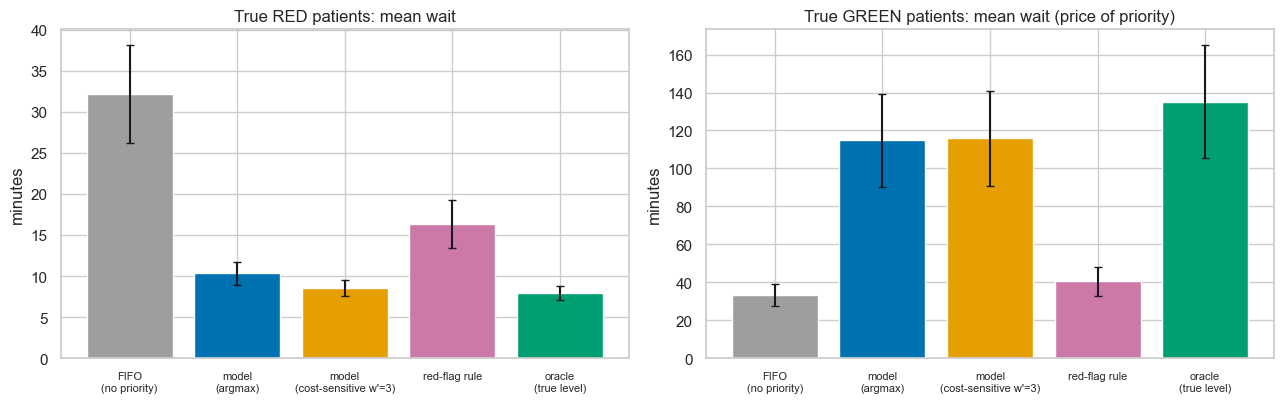

Assumptions: 3 treatment places, utilisation 90%, 150 patients per run, service means (red/yellow/green) = [12.0, 25.0, 40.0] min, 60 runs.


In [36]:
def simulate(arr, prio, svc, c=3, fifo=False):
    n = len(arr); order = np.argsort(arr, kind="stable"); free = [0.0] * c; heapq.heapify(free); heap = []; i = 0; started = 0; wait = np.zeros(n)
    while started < n:
        T = heapq.heappop(free)
        if not heap and i < n and arr[order[i]] > T: T = arr[order[i]]
        while i < n and arr[order[i]] <= T:
            j = order[i]; heapq.heappush(heap, (0 if fifo else -prio[j], arr[j], j)); i += 1
        _, _, j = heapq.heappop(heap); wait[j] = T - arr[j]; heapq.heappush(free, T + svc[j]); started += 1
    return wait

SERVICE_MEAN = np.array([12.0, 25.0, 40.0]); SERVERS, RHO, N_PAT, N_RUNS = 3, 0.90, 150, 60
POLICIES = {"FIFO (no priority)": None, "model (argmax)": "pred_model", f"model (cost-sensitive w'={W_STAR})": "pred_cs", "red-flag rule": "pred_rule", "oracle (true level)": "true_level"}
rng = np.random.default_rng(SEED + 11); recs = []
for run_ in range(N_RUNS):
    s = PT.sample(N_PAT, replace=True, random_state=int(rng.integers(1e9))); true = s.true_level.to_numpy(); means = SERVICE_MEAN[true]
    svc = rng.exponential(means); horizon = means.sum() / (SERVERS * RHO); arr = rng.uniform(0, horizon, N_PAT)
    for name, col in POLICIES.items():
        w_ = simulate(arr, None if col is None else s[col].to_numpy(), svc, SERVERS, fifo=(col is None))
        recs.append({"run": run_, "policy": name, "red_mean": w_[true == 2].mean(), "red_p90": np.percentile(w_[true == 2], 90), "yellow_mean": w_[true == 1].mean(), "green_mean": w_[true == 0].mean(), "all_mean": w_.mean()})
SIM = pd.DataFrame(recs)
agg = SIM.groupby("policy", sort=False).agg(["mean", "std"]); ci95 = lambda c: 1.96 * agg[(c, "std")] / np.sqrt(N_RUNS)
SIMT = pd.DataFrame({"red: mean wait (min)": agg[("red_mean", "mean")], "± 95% CI": ci95("red_mean"), "red: 90th pct (min)": agg[("red_p90", "mean")],
                     "yellow: mean wait": agg[("yellow_mean", "mean")], "green: mean wait": agg[("green_mean", "mean")], "all: mean wait": agg[("all_mean", "mean")]})
SIMT["red wait vs FIFO"] = SIMT["red: mean wait (min)"] / SIMT.loc["FIFO (no priority)", "red: mean wait (min)"] - 1
display(SIMT.round(2))

pol_col = {"FIFO (no priority)": "#9e9e9e", "model (argmax)": "#0072B2", f"model (cost-sensitive w'={W_STAR})": "#E69F00", "red-flag rule": "#CC79A7", "oracle (true level)": "#009E73"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a_, (c_, ttl) in zip(ax, [("red_mean", "True RED patients: mean wait"), ("green_mean", "True GREEN patients: mean wait (price of priority)")]):
    v_ = agg[(c_, "mean")]; e_ = ci95(c_); a_.bar(range(len(v_)), v_.values, yerr=e_.values, color=[pol_col[p] for p in v_.index], capsize=3)
    a_.set_xticks(range(len(v_))); a_.set_xticklabels([p.replace(" (", "\n(") for p in v_.index], fontsize=8); a_.set_ylabel("minutes"); a_.set_title(ttl)
plt.tight_layout(); plt.show()
print(f"Assumptions: {SERVERS} treatment places, utilisation {RHO:.0%}, {N_PAT} patients per run, service means (red/yellow/green) = {SERVICE_MEAN.tolist()} min, {N_RUNS} runs.")

## 5.8 Review process (CRISP-DM 5.2)
| Check | Status |
|---|---|
| Business objective and success criteria stated before modelling | done (§1.3) |
| Data quality problems found and documented (cell spill-over, decimal commas, `None` parsed as NaN, treatment text in `Examination_2`, duplicate and constant columns) | done (§2.4, §3.2) |
| Leakage checked (`Hazard`; suspicious `DiscomfortLevel`) with ablation and a feature set without it | done (§3.3.3, §4.4) |
| Test design before modelling; group-wise split; untouched hold-out | done (§4.2, §5.1) |
| Class imbalance handled; metrics beyond accuracy; uncertainty (cluster bootstrap) | done |
| Domain-expert comments (4.4.6) | **missing** – to obtain from Prof. Habib / a triage nurse |
| Calibration of the probabilities | **should be repeated / added** (affects §5.6) |
| Vital signs named in the course material (respiratory rate, capillary refill) | **not in the archive** – the model cannot use them |
| Real flow data (timestamps, waiting times, capacity) for Lean/Six Sigma | **missing** – §5.7 is illustrative only |
| Labels from the simulator vs. real clinical triage | **limitation** – results describe the archive, not a hospital |

## 5.9 Determine next steps (CRISP-DM 5.3)
| Option | For | Against | Decision |
|---|---|---|---|
| Stop here and report | criteria met, deadline | no expert validation, no calibration | – |
| Add calibration + ordinal models and re-tune the cost rule | cheap, improves §5.6 | modest gain | **do if time allows** |
| Connect the model to a simulator (HospitalSim) or to real flow data to measure waiting time | answers the Lean/optimisation question properly | needs data/access | **future work** |
| Extend to resource allocation (rooms, equipment, cost columns of the archive) as a scheduling optimisation | natural optimisation topic for the course | beyond Health02 scope | **future work / thesis proposal** |

# 6. Deployment (CRISP-DM phase 6)
## 6.1 Plan deployment
**Deployable outcomes:** (1) the trained triage model and its decision rule (cost-sensitive weight `w'`), (2) the explainable red-flag score and the shallow tree rules, (3) the findings about data quality and about which columns matter.

**Alternative deployment plans (lecture 6.1):**
| Option | Fit for triage | Verdict |
|---|---|---|
| Batch scoring of a patient list (file/database) | simple, cheap; suitable for retrospective audits and simulation studies | **used for the evaluation and the demo below** |
| Web service / REST API called by the triage desk system | near-real-time, one patient at a time, easy to integrate; needs security and logging | **recommended target** |
| Mobile / edge device at the scene | useful for mass-casualty triage; limited hardware, no network | possible later (the forest can be distilled into the shallow tree) |
| Real-time streaming | not needed: arrivals are discrete events | not recommended |

**Recommended operating mode: decision support with a human in the loop.** The tool proposes a colour and the probability of *red*; a nurse decides. Patients whose predicted level is below red but whose probability of red is high are flagged **“review”**. Because of hidden urgency (§5.2) patients are re-scored when new symptoms are revealed.

**Challenges and how to meet them:** the data are simulated (no clinical validity), probabilities are not calibrated, vital signs from the course material are not in the archive, and over-reliance on the tool is a safety risk – hence human oversight, logging of every recommendation, and a monitoring plan (§6.2).

In [37]:
# Alert burden of the 'review' flag, measured honestly on the 3,000 patients (predictions from models that never saw the diagnosis)
miss = (PT.true_level == 2) & (PT.pred_cs < 2); rows = []
for tau in [0.05, 0.10, 0.15, 0.25, 0.35, 0.50]:
    flag = (PT.pred_cs < 2) & (PT.maxP_high >= tau)
    rows.append({"threshold on P(red)": tau, "flagged": flag.mean(), "caught": int((flag & miss).sum()), "missed red patients": int(miss.sum())})
AB = pd.DataFrame(rows); AB["caught share"] = AB.caught / max(1, int(miss.sum()))
ok = AB[AB["caught share"] >= 0.5]
REVIEW_TAU = float(ok["threshold on P(red)"].max()) if len(ok) else float(AB["threshold on P(red)"].min())   # lowest alert burden that still catches >= 50 % of missed reds
show = AB.assign(flagged=AB.flagged.map("{:.1%}".format), caught=AB.caught.astype(str) + " of " + AB["missed red patients"].astype(str))[["threshold on P(red)", "flagged", "caught", "caught share"]]
show.columns = ["threshold on P(red)", "patients flagged for review", "missed red patients caught", "caught share"]
display(show.round(2))
print(f"Chosen review threshold: {REVIEW_TAU} (largest threshold that still catches >= 50 % of the missed red patients). Lower thresholds catch more but add alert burden for the nurses (a Lean trade-off).")
print(f"Only {int(miss.sum())} red patients are missed by the cost-sensitive rule in this sample, so this threshold is indicative, not precise.")

,threshold on P(red),patients flagged for review,missed red patients caught,caught share
0,0.05,14.1%,5 of 5,1.0
1,0.10,3.6%,1 of 5,0.2
2,0.15,0.8%,0 of 5,0.0
3,0.25,0.0%,0 of 5,0.0
4,0.35,0.0%,0 of 5,0.0
5,0.50,0.0%,0 of 5,0.0


Chosen review threshold: 0.05 (largest threshold that still catches >= 50 % of the missed red patients). Lower thresholds catch more but add alert burden for the nurses (a Lean trade-off).
Only 5 red patients are missed by the cost-sensitive rule in this sample, so this threshold is indicative, not precise.


In [38]:
# Train the deployable model on ALL archive rows and package it with a model card
final_model = fit_pipe(BEST_MODEL, FINAL_NUMS, FINAL_CATS, df)
joblib.dump(final_model, f"{OUT_DIR}/triage_model.joblib")
card = {"name": "Health02 triage model (IND310)", "model": BEST_MODEL, "feature_set": BEST_FS, "numeric_features": FINAL_NUMS, "categorical_features": FINAL_CATS,
        "uses_DiscomfortLevel": bool(BEST.uses_DiscomfortLevel), "decision_weight_w": W_STAR, "assumed_cost_ratio": ASSUMED_W, "review_threshold_P_red": REVIEW_TAU,
        "levels": {"0": "Low / green", "1": "Medium / yellow", "2": "High / red"}, "trained_on_rows": int(len(df)), "trained_on_diagnoses": int(df.Diagnosis.nunique()),
        "holdout_macro_f1": round(float(m_fin["macro_f1"]), 4), "holdout_red_recall": round(float(m_fin["recall_high"]), 4), "sklearn": sklearn.__version__, "seed": SEED,
        "intended_use": "decision support for triage in a SIMULATED hospital archive; human decides",
        "limitations": ["synthetic/simulated labels", "probabilities not calibrated", "no vital signs", "assumed cost ratio, not clinically validated"]}
json.dump(card, open(f"{OUT_DIR}/triage_model_card.json", "w"), indent=2)

def score_rows(X, model=final_model, w=W_STAR):
    # X: DataFrame with the model's feature columns, one row per presented symptom -> (probabilities, predicted level)
    proba = model.predict_proba(X[cols_final]); return proba, decide(proba, w)

def score_patients(P, frame=df, tau=REVIEW_TAU):
    out = []
    for _, pt in P.iterrows():
        proba, lv = score_rows(frame.loc[pt.presented_rows]); level = int(lv.max()); p_red = float(proba[:, 2].max())
        out.append({"patient_id": pt.patient_id, "Name": pt.Name, "arrival_time": pt.arrival_time, "symptoms": ", ".join(pt.Revealed_Symptoms), "predicted": COLOUR[level],
                    "P(red)": round(p_red, 3), "review": bool(level < 2 and p_red >= tau), "_lv": level})
    R = pd.DataFrame(out).sort_values(["_lv", "P(red)", "arrival_time"], ascending=[False, False, True]).reset_index(drop=True)
    R.insert(0, "queue position", np.arange(1, len(R) + 1)); return R.drop(columns="_lv")

new_batch = generate_patients(12, seed=2026)
queue = score_patients(new_batch)
queue["(true, for the demo)"] = new_batch.set_index("patient_id").loc[queue.patient_id, "true_colour"].to_numpy()
print("Priority queue for a new batch of 12 random patients:"); display(queue)
print("NB: the deployable model was trained on the whole archive, so these demo scores are optimistic. Honest performance = §5.1-5.2.")

Priority queue for a new batch of 12 random patients:


,queue position,patient_id,Name,arrival_time,symptoms,predicted,P(red),review,"(true, for the demo)"
0,1,8,Mina Berg,2026-03-17 16:37:13,"High Fever, Headache, Eye Pain",Red,0.546,False,Red
1,2,7,Henrik Nilsen,2026-11-19 15:00:44,"Hemoptysis, Breathing Problems, Edema",Yellow,0.070,True,Yellow
2,3,10,Tobias Hansen,2026-10-17 16:43:54,"Chest Pain, Chest Injury, Breathing Problems",Yellow,0.057,True,Yellow
3,4,11,Emma Haugen,2026-09-20 10:30:00,"Tenderness, Breathing Problems, Redness",Yellow,0.041,False,Yellow
4,5,3,Maja Karlsen,2026-06-12 13:00:59,"Photophobia, Poor Balance, Tinnitus",Yellow,0.027,False,Yellow
5,6,6,Thea Dahl,2026-10-13 13:35:10,"Hearing Problems, Thirst, Stiffness of the Neck",Yellow,0.027,False,Green
6,7,1,Ola Karlsen,2026-10-26 14:22:18,"Redness, Pain, Collarbone Injury",Yellow,0.013,False,Yellow
7,8,12,Jonas Larsen,2026-09-09 14:11:25,"Elbow Pain, Ulnar Claw, Hand Pain",Yellow,0.003,False,Yellow
8,9,5,Mats Pedersen,2026-03-12 10:25:58,"Fever, Pale Skin, Fatigue",Yellow,0.000,False,Yellow
9,10,4,Mina Larsen,2026-07-07 15:16:29,Chest Pain,Yellow,0.000,False,Yellow


NB: the deployable model was trained on the whole archive, so these demo scores are optimistic. Honest performance = §5.1-5.2.


## 6.2 Plan monitoring and maintenance
A model that passes testing can still become wrong: **data drift** (inputs change), **prediction drift** (more reds are predicted than before) or **concept shift** (the same inputs now mean something else). We implement the **Population Stability Index (PSI)** per feature (`< 0.10` stable, `0.10–0.25` watch, `> 0.25` investigate/retrain) and demonstrate it on three scenarios: a normal random batch, a *trauma surge* (patients only from trauma diagnoses) and a *sensor/schema failure* (DiscomfortLevel no longer recorded).

In [39]:
def psi(ref, new, bins=10):
    ref, new = pd.Series(ref).reset_index(drop=True), pd.Series(new).reset_index(drop=True)
    if pd.api.types.is_numeric_dtype(ref) and ref.nunique() > 8:
        edges = np.unique(np.quantile(ref.dropna(), np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
        f = lambda s: pd.cut(s, edges, include_lowest=True).astype(object).where(s.notna(), "missing").astype(str)
    else:
        f = lambda s: s.astype(object).where(s.notna(), "missing").astype(str)
    a, b = f(ref), f(new); cats = sorted(set(a) | set(b))
    pe = a.value_counts(normalize=True).reindex(cats, fill_value=0).clip(lower=1e-4); pn = b.value_counts(normalize=True).reindex(cats, fill_value=0).clip(lower=1e-4)
    return float(((pn - pe) * np.log(pn / pe)).sum())

rows_of = lambda P: df.loc[np.concatenate(P.presented_rows.to_list()), cols_final]
reference = df.loc[df.interview == 1, cols_final]                     # what patients can present: interview-revealed symptoms
trauma_dx = df.loc[df.avdeling == "trauma", "Diagnosis"].unique()
scen = {"normal random batch": generate_patients(1000, seed=SEED + 21),
        "trauma surge": generate_patients(1000, diagnoses=trauma_dx, seed=SEED + 22)}
frames = {k: rows_of(v) for k, v in scen.items()}
broken = frames["normal random batch"].copy(); broken["discomfort"] = np.nan; frames["DiscomfortLevel not recorded"] = broken

PSI = pd.DataFrame({k: {c: psi(reference[c], fr[c]) for c in cols_final} for k, fr in frames.items()})
status = lambda v: "stable" if v < .10 else ("watch" if v < .25 else "INVESTIGATE")
print("Features per status:"); display(PSI.apply(lambda col: col.map(status).value_counts()).fillna(0).astype(int).T)
print("Largest PSI values:"); display(PSI.loc[PSI.max(axis=1).sort_values(ascending=False).head(8).index].round(2))

# does input drift translate into worse triage? (honest predictions: unseen diagnoses)
perf = {}
for k, P in scen.items():
    P = P.copy(); P["pred_cs"] = patient_max(P, PRED_ROW_CS); perf[k] = pt_metrics(P, "pred_cs")
display(pd.DataFrame(perf).T[["patients", "red patients", "red recall", "under-triage", "over-triage", "accuracy"]].round(3))
print(f"Fallback if DiscomfortLevel is not recorded: the model trained without it (FS3b) reaches macro-F1 {bd.loc[FS3B, 'macro_f1']:.2f} and red recall {bd.loc[FS3B, 'recall_high']:.2f} in cross-validation - red recall holds, but over-triage rises to {bd.loc[FS3B, 'over_triage']:.0%}, so switch to that model and warn the nurses.")

Features per status:


,INVESTIGATE,stable,watch
normal random batch,0,23,1
trauma surge,10,10,4
DiscomfortLevel not recorded,1,22,1


Largest PSI values:


,normal random batch,trauma surge,DiscomfortLevel not recorded
avdeling,0.01,8.49,0.01
discomfort,0.01,0.65,8.30
p_crit,0.01,2.04,0.01
collapse_window,0.00,0.57,0.00
collapse_end,0.00,0.56,0.00
collapse_symptom,0.01,0.55,0.01
collapse_start,0.00,0.47,0.00
has_collapse,0.00,0.45,0.00


,patients,red patients,red recall,under-triage,over-triage,accuracy
normal random batch,1000.0,157.0,0.987,0.005,0.098,0.897
trauma surge,1000.0,465.0,1.000,0.000,0.092,0.908


Fallback if DiscomfortLevel is not recorded: the model trained without it (FS3b) reaches macro-F1 0.76 and red recall 0.91 in cross-validation - red recall holds, but over-triage rises to 14%, so switch to that model and warn the nurses.


**Monitoring and maintenance plan**
| What | How often | Trigger | Action |
|---|---|---|---|
| Input drift (PSI per feature, share of missing values) | every batch / daily | PSI > 0.25 on any feature, or a feature suddenly missing | check data feed; fall back to the red-flag rule |
| Prediction drift (share of red / yellow / green predicted) | weekly | share changes > 5 percentage points | investigate case mix (e.g. surge) |
| Under-triage rate on clinician-confirmed cases (needs real labels) | monthly | red recall < 0.90 | re-train, re-tune `w'` |
| Calibration and review-flag burden | monthly | alerts per nurse shift above agreed limit | adjust the review threshold |
| Change of the triage protocol or of the archive | at every change | any | re-run this notebook end to end (CRISP-DM iteration) |

**Retirement criteria:** red recall below 0.90 for two consecutive monitoring periods, or a change of the triage system (e.g. other colour definitions). **A/B testing** (lecture 6.2) is the right way to introduce a new model version: half of the shifts use version B in shadow mode, the nurses' decisions are compared before B is allowed to influence the queue.

## 6.3 Produce final report – how this notebook maps to the report
The report follows the *Project definition* template. The notebook provides the content; the report needs your own writing, literature and discussion.

| Report section (project definition) | Source in this notebook | Still to be written by you |
|---|---|---|
| Title, abstract | – | after results are final (purpose, data, methods, key numbers, implication) |
| Introduction, **problem statement**, **research questions** | §1.1–1.2, §1.4 | industrial context + stakeholder (emergency department), 1 main question + 2–4 sub-questions |
| Related work (knowledge gap) | – | literature on triage, ML for triage, Six Sigma/Lean in healthcare |
| Theory | §1.5 (CRISP-DM, Six Sigma, Lean, optimisation) | concepts used in the analysis, conceptual model |
| **Data description** | §2.1–2.4, §3.1 (column dictionary, quality) | keep to the facts; leave analysis for later |
| **Methods** | §3.2–3.5, §4.1–4.3 (cleaning rules, features, test design, models, tuning) | justification of choices and validity |
| **Results** | §4.4, §5.1–5.2 | tables and figures with captions; state facts without interpretation |
| **Analysis** | §5.3–5.7 | link evidence to claims |
| **Discussion** | §5.8–5.9, §6 | meaning, limits (simulated data!), implications for the stakeholder KPIs |
| Conclusion, future work | §5.9, §6.4 | answer the research questions directly |
| Appendix | the notebook, `outputs/` files | short description of each appendix item |

## 6.4 Review project
**What went well:** the group-wise test design exposed that row-wise splitting would have inflated the scores; the grouped importance analysis separated the information carried by several repeated columns; the success criteria were fixed before modelling.

**What went wrong or was hard:** the CSV has quality problems (spill-over text, decimal commas, `None` read as NaN, treatment text in an examination column) that only appear when the data are read carefully; the label is symptom-level, not patient-level; the strongest column (`DiscomfortLevel`) is close to a proxy for the label.

**Pitfalls to remember:** do not use `Hazard` (leakage); do not split rows randomly; do not judge by accuracy; do not claim clinical validity.

**Generalise to future projects:** write the cleaning report while cleaning; define the unit (symptom vs patient) first; report uncertainty with the unit of independence (diagnosis) as cluster.

**Future work:** expert validation of the labels; calibration and ordinal models; real flow data to calibrate the Lean simulation; connect to HospitalSim or a similar simulator; resource allocation (rooms, equipment, cost) as an optimisation problem on top of the triage level.

In [40]:
def to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return str(o)

SUMMARY = {
 "data": {"rows_raw": int(len(raw)), "rows_clean": int(len(df)), "columns": int(raw.shape[1]), "diagnoses": int(df.Diagnosis.nunique()), "class_share": df.triage_level.value_counts(normalize=True).round(3).to_dict()},
 "selected": {"model": BEST_MODEL, "feature_set": BEST_FS, "uses_DiscomfortLevel": bool(BEST.uses_DiscomfortLevel), "rf_tuned_params": RF_TUNED},
 "cv_development": {k: round(float(BEST[k]), 4) for k in ["macro_f1", "macro_f1_sd", "recall_high", "recall_high_sd", "under_triage", "over_triage", "accuracy", "roc_auc_ovr"]},
 "holdout_test": {"metrics": {k: round(float(v), 4) for k, v in m_fin.items()}, "ci95": ci_fin.round(4).to_dict()},
 "without_DiscomfortLevel_cv": {"macro_f1": round(float(bd.loc[FS3B, "macro_f1"]), 4), "red_recall": round(float(bd.loc[FS3B, "recall_high"]), 4)},
 "with_DiscomfortLevel_cv": {"macro_f1": round(float(bd.loc["FS3 + archive knowledge", "macro_f1"]), 4), "red_recall": round(float(bd.loc["FS3 + archive knowledge", "recall_high"]), 4)},
 "patient_level_argmax": pt_metrics(PT, "pred_model"), "patient_level_rule": pt_metrics(PT, "pred_rule"), "patient_level_cost_sensitive": pt_metrics(PT, "pred_cs"),
 "hidden_urgency_share": float(hidden.mean()),
 "six_sigma": SS.to_dict(orient="index"), "six_sigma_cost_sensitive": SS_CS.to_dict(orient="index"), "review_threshold": REVIEW_TAU, "decision_weight": {"assumed_w": ASSUMED_W, "w_star": W_STAR},
 "queue_simulation_minutes": SIMT.round(2).to_dict(orient="index"),
 "sensitivity_5_splits": {"macro_f1_mean": round(float(SENS.macro_f1.mean()), 4), "macro_f1_sd": round(float(SENS.macro_f1.std()), 4), "red_recall_mean": round(float(SENS.recall_high.mean()), 4), "red_recall_min": round(float(SENS.recall_high.min()), 4)},
 "column_verdicts": final_verdict.verdict.value_counts().to_dict(), "top_groups": IMP.head(6)[["impact", "verdict"]].round(4).to_dict(orient="index"),
}
json.dump(SUMMARY, open(f"{OUT_DIR}/results_summary.json", "w"), indent=2, default=to_py)
print("KEY RESULTS (also saved to outputs/results_summary.json)")
print(f"- Selected: {BEST_MODEL} on '{BEST_FS}' (uses DiscomfortLevel: {bool(BEST.uses_DiscomfortLevel)})")
print(f"- Development CV (unseen diagnoses): macro-F1 {BEST.macro_f1:.3f}, red recall {BEST.recall_high:.3f}")
print(f"- Hold-out test: macro-F1 {m_fin['macro_f1']:.3f} {ci_fin.loc['macro_f1', ['ci_low', 'ci_high']].round(3).tolist()}, red recall {m_fin['recall_high']:.3f} {ci_fin.loc['recall_high', ['ci_low', 'ci_high']].round(3).tolist()}")
print(f"- Patient level (3,000 random patients): red recall {pt_metrics(PT, 'pred_model')['red recall']:.3f} (argmax), {pt_metrics(PT, 'pred_cs')['red recall']:.3f} (cost-sensitive, w'={W_STAR}); sigma level {SS.loc['model (argmax)', 'sigma level']}")
print("\nFiles written to", OUT_DIR + "/:"); print(", ".join(sorted(os.listdir(OUT_DIR))))

KEY RESULTS (also saved to outputs/results_summary.json)
- Selected: Random forest (tuned) on 'FS3 + archive knowledge' (uses DiscomfortLevel: True)
- Development CV (unseen diagnoses): macro-F1 0.888, red recall 0.919
- Hold-out test: macro-F1 0.897 [0.869, 0.922], red recall 0.967 [0.933, 0.993]
- Patient level (3,000 random patients): red recall 0.898 (argmax), 0.990 (cost-sensitive, w'=3); sigma level 2.77

Files written to outputs/:
column_selection_table.csv, data_cleaning_report.csv, feature_importance.csv, feature_screening.csv, final_column_verdict.csv, results_summary.json, triage_model.joblib, triage_model_card.json, triage_model_frame.csv
